# When the Earth Draws Its Own Map
## Unsupervised Discovery of Seismic Regimes in 50 Years of Significant Earthquakes (1965–2016)

**23CSE301 Machine Learning — Capstone Project, Review 2 · Clustering Track**
**Group:** DATA MINDS  ·  **Dataset:** `database.csv` — USGS / ANSS catalogue of significant earthquakes (magnitude ≥ 5.5), 1965–2016

---

### The question behind this notebook

Geologists spent most of the 20th century working out that the Earth's surface is broken into tectonic plates, and that
earthquakes happen where those plates grind, collide and sink. **Our question is simple: if we give a machine nothing
but *where* an earthquake happened and *how deep* it was — no plate maps, no geology, no labels — can it rediscover that
structure on its own?**

If it can, the clusters are not just "groups of points". They are *seismic regimes*: places that shake for the same
physical reason. That turns clustering into something useful — given a new event, we can say which regime it belongs to,
what that regime historically does, and whether the event looks *natural at all*.

### How this notebook is organised

| Part | What we do | Rubric link |
|---|---|---|
| **Chapters 1–7 — The data tells its story** | Audit, data-quality detective work, where/how deep/how big/when, and the hidden nuclear tests | context for B1–B3, D1 |
| **Chapter 8 — Preparing the data** | Cleaning, the date-line problem, feature engineering, leakage-safe scaling | C1 |
| **Chapter 9 — K-Means** | Elbow curve, silhouette/DB/CH scan, final model | B1, B2 |
| **Chapter 10 — Agglomerative** | Dendrogram, four linkage strategies compared, final model | B1, B2 |
| **Chapter 11 — Evaluation** | Silhouette, Davies–Bouldin, Calinski–Harabasz on train **and** test | B2 |
| **Chapter 12 — Seeing the clusters** | PCA (every algorithm), t-SNE (both), and the clusters on a world map | B3 |
| **Chapter 13 — What the clusters mean** | Naming the regimes, depth/size behaviour, per-regime Gutenberg–Richter | D1, D2 |
| **Chapter 14 — Validation after the fact** | Labels used only *after* fitting: depth classes and the nuclear-test anomaly test | B2, D2 |
| **Chapter 15 — Saving models for the GUI** | Artefacts used by the Streamlit app | Bonus |
| **Chapter 16 — Conclusion** | Summary table, answers, limitations | D1 |

## 0. Setup
All randomness is seeded with `random_state = 42` (guideline 7.1). We use colour-blind-friendly palettes (`tab10`,
Seaborn `colorblind`) throughout (guideline 7.3).

In [1]:
# ---- Core libraries ----
import os, json, warnings
import numpy as np
import pandas as pd

# ---- Visualisation ----
import matplotlib.pyplot as plt
import seaborn as sns

# ---- Machine learning ----
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment
from scipy import stats
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
CLUSTER_PALETTE = plt.get_cmap("tab10").colors   # 10 distinct, colour-blind-friendly colours

# Works whether the notebook is run from notebooks/ (as in the repo) or from the repository root
ROOT = ".." if os.path.exists("../data/database.csv") else "."
DATA_PATH = os.path.join(ROOT, "data", "database.csv")
MODEL_DIR = os.path.join(ROOT, "models")
os.makedirs(MODEL_DIR, exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.2 | numpy 2.4.4


---
# Chapter 1 — Meet the data
## 1.1 Loading and auditing the catalogue
Each row is one seismic event recorded by the global network. We first check shape, data types, missing values and the
distribution of the `Type` column (the only categorical "label" in the file — we will **not** use it for fitting).

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", raw.shape)
display(raw.head())

Shape (rows, columns): (23412, 21)


,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Magnitude Seismic Stations,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status
0,01/02/1965,13:44:18,19.246,145.616,Earthquake,131.6,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic
1,01/04/1965,11:29:49,1.863,127.352,Earthquake,80.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic
2,01/05/1965,18:05:58,-20.579,-173.972,Earthquake,20.0,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic
3,01/08/1965,18:49:43,-59.076,-23.557,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic
4,01/09/1965,13:32:50,11.938,126.427,Earthquake,15.0,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic


In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique_values": raw.nunique(),
}).sort_values("missing_%", ascending=False)
display(audit)

,dtype,missing,missing_%,unique_values
Magnitude Error,float64,23085,98.6,100
Horizontal Error,float64,22256,95.1,186
Horizontal Distance,float64,21808,93.1,1448
Magnitude Seismic Stations,float64,20848,89.0,246
Depth Error,float64,18951,80.9,297
Depth Seismic Stations,float64,16315,69.7,736
Azimuthal Gap,float64,16113,68.8,1109
Root Mean Square,float64,6060,25.9,190
Type,str,0,0.0,4
Date,str,0,0.0,12401


In [4]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate event IDs :", raw["ID"].duplicated().sum())
display(raw["Type"].value_counts().rename("events").to_frame())
display(raw[["Latitude", "Longitude", "Depth", "Magnitude"]].describe().T.round(2))

Exact duplicate rows: 0
Duplicate event IDs : 0


,events
Type,
Earthquake,23232
Nuclear Explosion,175
Explosion,4
Rock Burst,1


,count,mean,std,min,25%,50%,75%,max
Latitude,23412.0,1.68,30.11,-77.08,-18.65,-3.57,26.19,86.0
Longitude,23412.0,39.64,125.51,-180.00,-76.35,103.98,145.03,180.0
Depth,23412.0,70.77,122.65,-1.10,14.52,33.00,54.00,700.0
Magnitude,23412.0,5.88,0.42,5.50,5.60,5.70,6.00,9.1


**What the audit tells us**

* **23,412 events × 21 columns**, no duplicate rows and no duplicate IDs — the catalogue is clean at the record level.
* The four columns that describe the event itself (**Latitude, Longitude, Depth, Magnitude**) are **100 % complete**.
* The "quality" columns (*Depth Error, Magnitude Error, Horizontal Error, Azimuthal Gap…*) are 69–99 % empty.
  That is not random — we show in Chapter 2 that it is a fingerprint of *when* the event was recorded.
* Magnitude starts at exactly **5.5** — this is a **truncated** catalogue: only "significant" earthquakes made it in.
  Every conclusion we draw is about the big ones, not about the millions of small tremors each year.
* Not every row is an earthquake: **175 nuclear explosions, 4 other explosions and 1 rock burst** are hiding in here.
  Chapter 7 is about them.

---
# Chapter 2 — The data's own biography (data-quality detective work)
A dataset that spans 50 years is also a record of how *measurement* changed. Before trusting any pattern we ask:
*is this the Earth talking, or the instruments?*

In [5]:
# Parse dates. Three rows store a full ISO timestamp instead of MM/DD/YYYY — handle both formats.
dt = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%m/%d/%Y %H:%M:%S", errors="coerce")
bad_dates = dt.isna()
print("Rows with non-standard date format:", bad_dates.sum())
display(raw.loc[bad_dates, ["Date", "Time"]])
iso = pd.to_datetime(raw.loc[bad_dates, "Date"], utc=True).dt.tz_localize(None)
raw["Datetime"] = dt.fillna(iso)
raw["Year"] = raw["Datetime"].dt.year
raw["Decade"] = (raw["Year"] // 10) * 10
print("Unparseable dates remaining:", raw["Datetime"].isna().sum())
print("Range:", raw["Datetime"].min(), "→", raw["Datetime"].max())

Rows with non-standard date format: 3


,Date,Time
3378,1975-02-23T02:58:41.000Z,1975-02-23T02:58:41.000Z
7512,1985-04-28T02:53:41.530Z,1985-04-28T02:53:41.530Z
20650,2011-03-13T02:23:34.520Z,2011-03-13T02:23:34.520Z


Unparseable dates remaining: 0
Range: 1965-01-02 13:44:18 → 2016-12-30 20:08:28


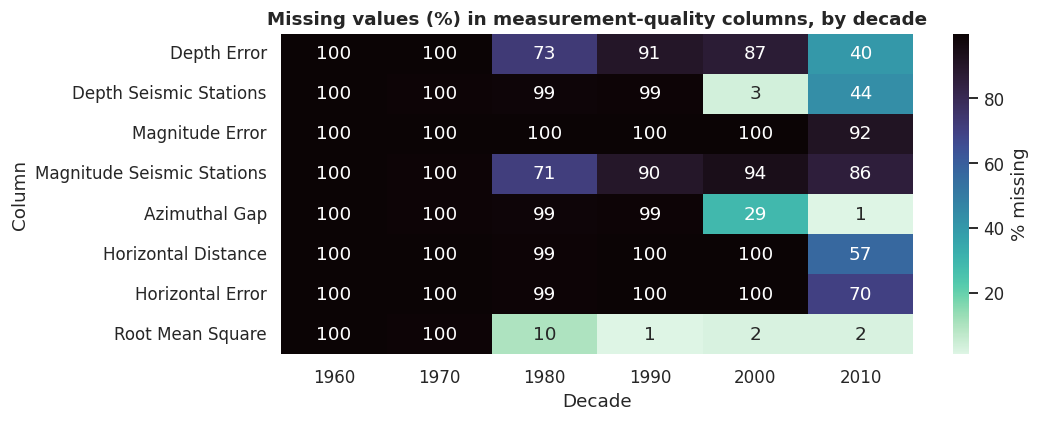

In [6]:
# 2.1 Missingness of the quality columns, decade by decade
quality_cols = ["Depth Error", "Depth Seismic Stations", "Magnitude Error", "Magnitude Seismic Stations",
                "Azimuthal Gap", "Horizontal Distance", "Horizontal Error", "Root Mean Square"]
miss_by_decade = raw.groupby("Decade")[quality_cols].apply(lambda g: g.isna().mean() * 100)

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(miss_by_decade.T, annot=True, fmt=".0f", cmap="mako_r", cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values (%) in measurement-quality columns, by decade")
ax.set_xlabel("Decade"); ax.set_ylabel("Column")
plt.tight_layout(); plt.show()

**Observation.** The empty cells are *historical*, not random. In the 1960s–70s almost nothing except the location and
size was stored; uncertainty estimates appear in the 1980s, and only in the 2010s do most events carry a depth error.
Imputing these columns would mean inventing 1960s instrument errors that were never measured — so we **do not use them as
clustering features**. This is a *justified* missing-value strategy: drop the columns, not the rows.

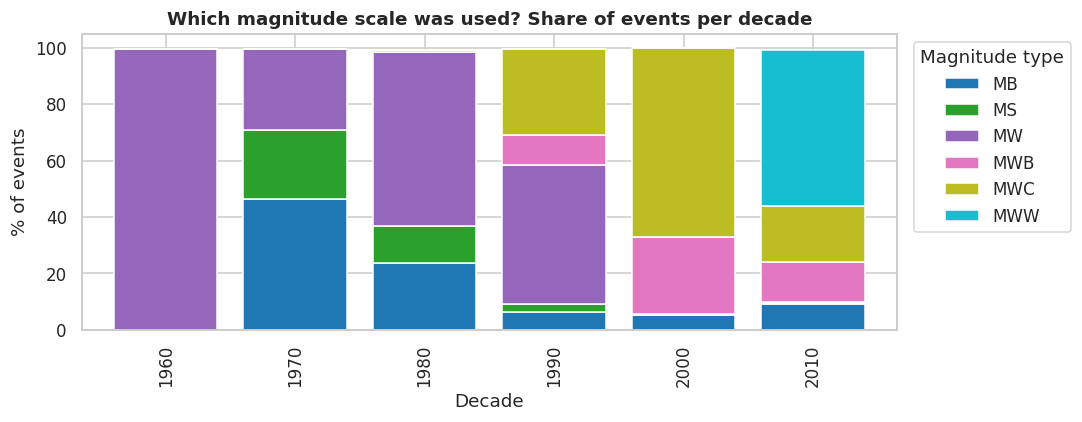

In [7]:
# 2.2 How magnitude was measured changed over time
mt = pd.crosstab(raw["Decade"], raw["Magnitude Type"], normalize="index") * 100
mt = mt.loc[:, mt.max() > 2]   # keep the scales that matter
ax = mt.plot(kind="bar", stacked=True, figsize=(10, 4), colormap="tab10", width=0.8)
ax.set_title("Which magnitude scale was used? Share of events per decade")
ax.set_xlabel("Decade"); ax.set_ylabel("% of events")
ax.legend(title="Magnitude type", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Observation.** The column called `Magnitude` is really several different rulers glued together. In the 1970s about
half the events use body-wave magnitude (**MB**) and a quarter surface-wave (**MS**); from the 1990s the moment-magnitude
family (**MW, MWC, MWB, MWW**) takes over. MB is known to *saturate* — it stops growing for very large quakes. So a
"5.8" from 1975 and a "5.8" from 2012 are not perfectly comparable. We keep magnitude **out** of the clustering features
and use it only to *describe* clusters afterwards.

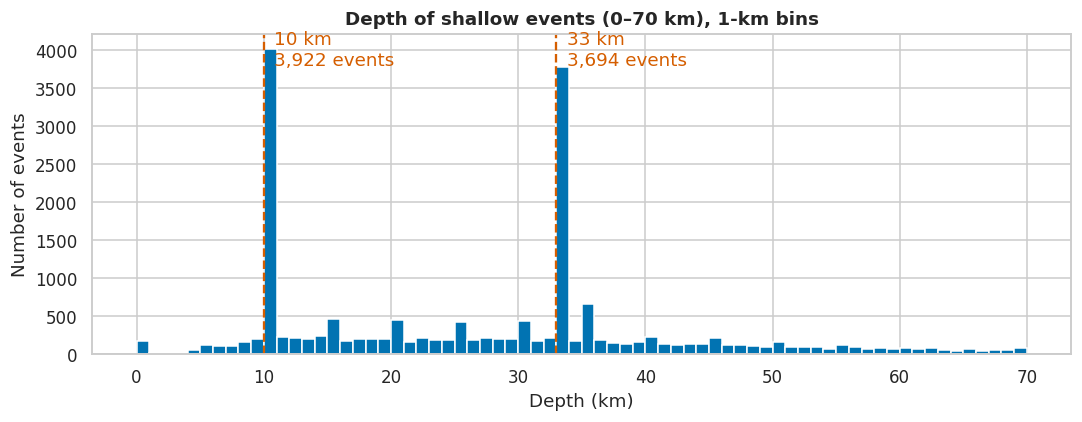

Events at exactly 10 km or 33 km: 32.5% of the catalogue


In [8]:
# 2.3 The suspicious depths
depth_counts = raw["Depth"].round(1).value_counts()
fig, ax = plt.subplots(figsize=(10, 4))
shallow = raw.loc[raw["Depth"] <= 70, "Depth"]
ax.hist(shallow, bins=np.arange(0, 71, 1), color="#0173b2", edgecolor="white")
for d in (10, 33):
    ax.axvline(d, color="#d55e00", ls="--", lw=1.5)
    ax.text(d + 0.8, ax.get_ylim()[1] * 0.9, f"{d} km\n{depth_counts.get(float(d), 0):,} events", color="#d55e00")
ax.set_title("Depth of shallow events (0–70 km), 1-km bins")
ax.set_xlabel("Depth (km)"); ax.set_ylabel("Number of events")
plt.tight_layout(); plt.show()
fixed_share = raw["Depth"].round(1).isin([10.0, 33.0]).mean() * 100
print(f"Events at exactly 10 km or 33 km: {fixed_share:.1f}% of the catalogue")

**Observation — one of the most interesting facts in this dataset.** About **a third of all events sit at exactly 10 km
or 33 km**. The Earth does not prefer those numbers; seismologists do. When the depth of a shallow quake cannot be pinned
down, the location software *fixes* it at a default — historically 33 km (a typical crust thickness), later 10 km. These
are honest "we don't know exactly, but it's shallow" markers.

**What it means for us:** depth is reliable at the *shallow vs intermediate vs deep* level, but not to the kilometre for
shallow quakes. That is one reason we use **log-depth** later — it compresses the 10-vs-33 distinction and emphasises the
physically meaningful jump from tens to hundreds of kilometres.

---
# Chapter 3 — Where does the Earth shake?
We have not loaded a single coastline or plate boundary. Every shape in the plot below is drawn by earthquakes alone.

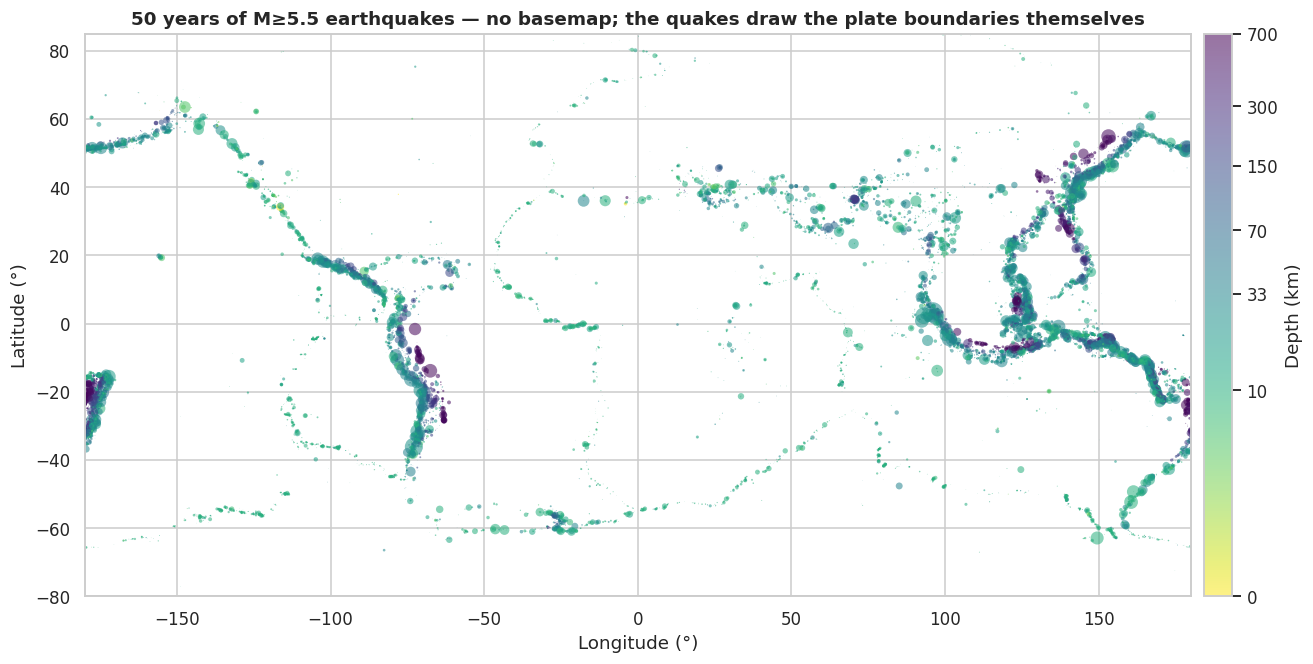

In [9]:
quakes_all = raw[raw["Type"] == "Earthquake"]
fig, ax = plt.subplots(figsize=(13, 6.2))
sc = ax.scatter(quakes_all["Longitude"], quakes_all["Latitude"], c=np.log1p(quakes_all["Depth"].clip(lower=0)),
                s=(quakes_all["Magnitude"] - 5.2) ** 3 * 3, cmap="viridis_r", alpha=0.55, linewidths=0)
cb = plt.colorbar(sc, ax=ax, pad=0.01)
ticks = [0, 10, 33, 70, 150, 300, 700]
cb.set_ticks(np.log1p(ticks)); cb.set_ticklabels(ticks); cb.set_label("Depth (km)")
ax.set_xlim(-180, 180); ax.set_ylim(-80, 85)
ax.set_title("50 years of M≥5.5 earthquakes — no basemap; the quakes draw the plate boundaries themselves")
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
plt.tight_layout(); plt.show()

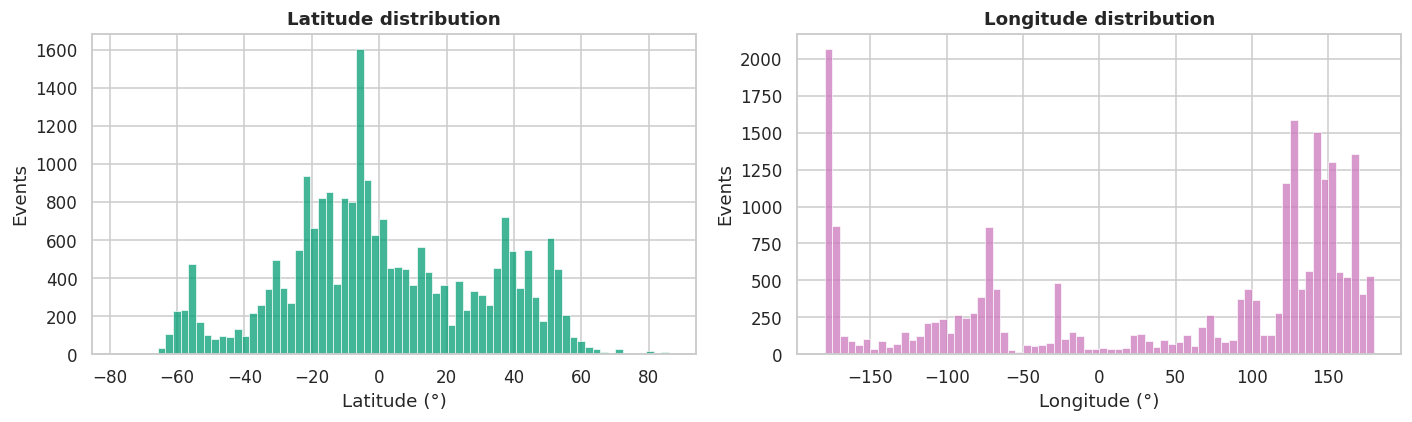

Share of earthquakes with longitude > 120°E or < 60°W (the Pacific rim, roughly): 79.6%
Southern-hemisphere share: 54.9%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(quakes_all["Latitude"], bins=72, ax=axes[0], color="#029e73")
axes[0].set_title("Latitude distribution"); axes[0].set_xlabel("Latitude (°)"); axes[0].set_ylabel("Events")
sns.histplot(quakes_all["Longitude"], bins=72, ax=axes[1], color="#cc78bc")
axes[1].set_title("Longitude distribution"); axes[1].set_xlabel("Longitude (°)"); axes[1].set_ylabel("Events")
plt.tight_layout(); plt.show()

pacific = ((quakes_all["Longitude"] > 120) | (quakes_all["Longitude"] < -60))
print(f"Share of earthquakes with longitude > 120°E or < 60°W (the Pacific rim, roughly): {pacific.mean()*100:.1f}%")
print(f"Southern-hemisphere share: {(quakes_all['Latitude'] < 0).mean()*100:.1f}%")

**Observations**

* The **Pacific "Ring of Fire"** is unmistakable — Japan, the Aleutians, Alaska, the Americas, Indonesia, Tonga, New
  Zealand. Roughly **four out of five** big earthquakes sit on the Pacific rim.
* Fainter thin lines run through the middle of the oceans — the **mid-ocean ridges** where plates pull apart. These are
  almost always shallow (yellow).
* A broad band runs from the Mediterranean through Turkey, Iran and the Himalaya — the **Alpine–Himalayan belt**, where
  Africa and India push into Eurasia.
* Large blank areas — Australia, Brazil, Canada, Siberia, most of Africa — are old, stable continental interiors.
* The longitude histogram has huge piles at both edges, near **+180° and −180°**. That is *one* region (Tonga–Fiji)
  artificially cut in half by the map. Remember this — it becomes a central design decision in Chapter 8.

---
# Chapter 4 — How deep does the Earth break?

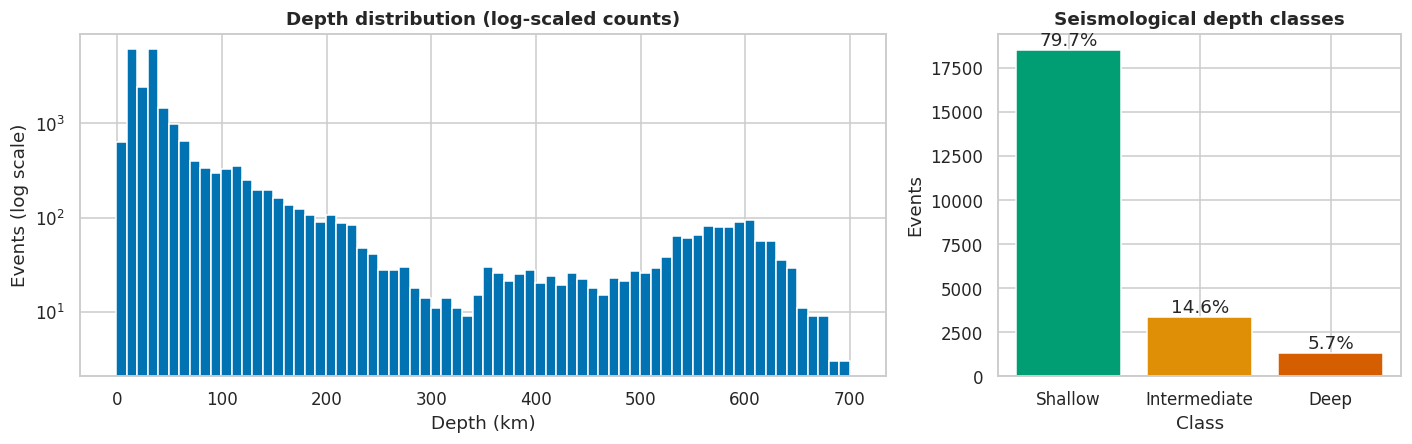

Skewness of depth: 3.28 | skewness of log(1+depth): 0.83


In [11]:
quakes_all = quakes_all.assign(DepthClass=pd.cut(quakes_all["Depth"], [-10, 70, 300, 800],
                                                 labels=["Shallow (<70 km)", "Intermediate (70–300 km)", "Deep (>300 km)"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].hist(quakes_all["Depth"], bins=70, color="#0173b2", edgecolor="white", log=True)
axes[0].set_title("Depth distribution (log-scaled counts)"); axes[0].set_xlabel("Depth (km)"); axes[0].set_ylabel("Events (log scale)")
dc = quakes_all["DepthClass"].value_counts().sort_index()
axes[1].bar(range(3), dc.values, color=["#029e73", "#de8f05", "#d55e00"])
axes[1].set_xticks(range(3)); axes[1].set_xticklabels(["Shallow", "Intermediate", "Deep"])
for i, v in enumerate(dc.values):
    axes[1].text(i, v, f"{v/dc.sum()*100:.1f}%", ha="center", va="bottom")
axes[1].set_title("Seismological depth classes"); axes[1].set_xlabel("Class"); axes[1].set_ylabel("Events")
plt.tight_layout(); plt.show()
print("Skewness of depth:", round(quakes_all["Depth"].skew(), 2),
      "| skewness of log(1+depth):", round(np.log1p(quakes_all["Depth"].clip(lower=0)).skew(), 2))

**Observation.** About **80 %** of big earthquakes are shallow, but the tail goes all the way to **700 km** — and
there is a second bump around **500–650 km**. Rock that deep should be too hot and soft to snap. Those quakes happen
inside cold slabs of ocean floor that have been *pushed down* into the mantle at subduction zones. The cross-section
below makes this visible.

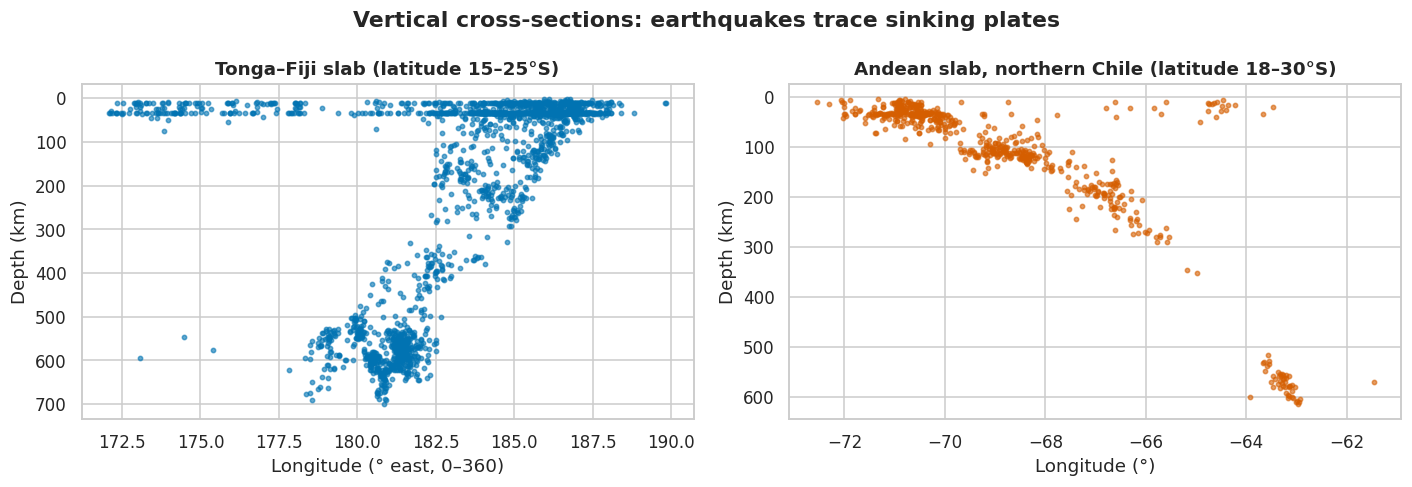

In [12]:
# Cross-section through the Tonga–Fiji region. Longitudes are converted to 0–360° so the region is not split at ±180°.
lon360 = quakes_all["Longitude"] % 360
tonga = quakes_all[(quakes_all["Latitude"].between(-25, -15)) & (lon360.between(172, 190))]
chile = quakes_all[(quakes_all["Latitude"].between(-30, -18)) & (quakes_all["Longitude"].between(-75, -60))]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(tonga["Longitude"] % 360, tonga["Depth"], s=8, alpha=0.6, color="#0173b2")
axes[0].invert_yaxis(); axes[0].set_title("Tonga–Fiji slab (latitude 15–25°S)")
axes[0].set_xlabel("Longitude (° east, 0–360)"); axes[0].set_ylabel("Depth (km)")
axes[1].scatter(chile["Longitude"], chile["Depth"], s=8, alpha=0.6, color="#d55e00")
axes[1].invert_yaxis(); axes[1].set_title("Andean slab, northern Chile (latitude 18–30°S)")
axes[1].set_xlabel("Longitude (°)"); axes[1].set_ylabel("Depth (km)")
plt.suptitle("Vertical cross-sections: earthquakes trace sinking plates", fontweight="bold")
plt.tight_layout(); plt.show()

**Observation — we are literally seeing a plate sink.** In both panels the quakes form a tilted line: shallow at the
trench, getting deeper as you move away from it. This is a **Wadati–Benioff zone**, the outline of an ocean plate diving
into the mantle. The Pacific plate under Tonga dives to ~700 km and dips *westward*; the Nazca plate under South America
dips *eastward* and, in this section, mostly stops near 300 km before a few isolated very deep events. Depth carries real
physical information — which is why it is one of our clustering features.

---
# Chapter 5 — How big? The 50-year law of earthquake sizes

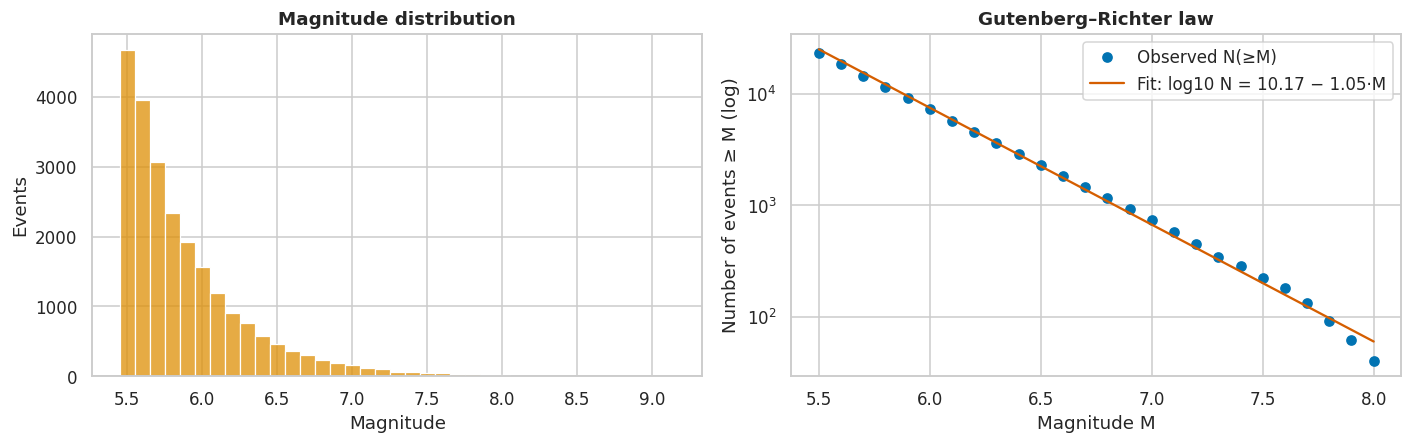

b-value = 1.05
M≥6:  7296 events  → about one every     2.6 days
M≥7:   738 events  → about one every    25.7 days
M≥8:    40 events  → about one every   474.8 days
M≥9:     2 events  → about one every  9496.5 days


In [13]:
M = np.round(np.arange(5.5, 8.01, 0.1), 1)
N_ge = np.array([(quakes_all["Magnitude"] >= m - 1e-9).sum() for m in M])
b_slope, a_int = np.polyfit(M, np.log10(N_ge), 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(quakes_all["Magnitude"], bins=np.arange(5.45, 9.2, 0.1), ax=axes[0], color="#de8f05")
axes[0].set_title("Magnitude distribution"); axes[0].set_xlabel("Magnitude"); axes[0].set_ylabel("Events")
axes[1].semilogy(M, N_ge, "o", color="#0173b2", label="Observed N(≥M)")
axes[1].semilogy(M, 10 ** (a_int + b_slope * M), "-", color="#d55e00", label=f"Fit: log10 N = {a_int:.2f} − {-b_slope:.2f}·M")
axes[1].set_title("Gutenberg–Richter law"); axes[1].set_xlabel("Magnitude M"); axes[1].set_ylabel("Number of events ≥ M (log)")
axes[1].legend()
plt.tight_layout(); plt.show()
print(f"b-value = {-b_slope:.2f}")
for t in (6, 7, 8, 9):
    n = (quakes_all["Magnitude"] >= t).sum()
    print(f"M≥{t}: {n:5d} events  → about one every {52*365.25/max(n,1):7.1f} days")

In [14]:
top10 = (raw[raw["Type"] == "Earthquake"].nlargest(12, "Magnitude")
         [["Datetime", "Latitude", "Longitude", "Depth", "Magnitude", "Magnitude Type"]])
top10.insert(0, "Known as", ["Sumatra–Andaman (Indian Ocean tsunami)", "Tōhoku, Japan (Fukushima tsunami)",
                             "Maule, Chile", "Rat Islands, Alaska", "Nias, Indonesia", "Off northern Sumatra",
                             "Southern Peru", "Southern Sumatra", "Kuril Islands (Shikotan)", "Tokachi-oki, Hokkaido",
                             "Kuril Islands", "Sea of Okhotsk (deep)"][:len(top10)])
display(top10.reset_index(drop=True))

,Known as,Datetime,Latitude,Longitude,Depth,Magnitude,Magnitude Type
0,Sumatra–Andaman (Indian Ocean tsunami),2004-12-26 00:58:53,3.295,95.982,30.0,9.1,MW
1,"Tōhoku, Japan (Fukushima tsunami)",2011-03-11 05:46:24,38.297,142.373,29.0,9.1,MWW
2,"Maule, Chile",2010-02-27 06:34:12,-36.122,-72.898,22.9,8.8,MWW
3,"Rat Islands, Alaska",1965-02-04 05:01:22,51.251,178.715,30.3,8.7,MW
4,"Nias, Indonesia",2005-03-28 16:09:37,2.085,97.108,30.0,8.6,MWW
5,Off northern Sumatra,2012-04-11 08:38:37,2.327,93.063,20.0,8.6,MW
6,Southern Peru,2001-06-23 20:33:14,-16.265,-73.641,33.0,8.4,MWW
7,Southern Sumatra,2007-09-12 11:10:27,-4.438,101.367,34.0,8.4,MWW
8,Kuril Islands (Shikotan),1994-10-04 13:22:56,43.773,147.321,14.0,8.3,MW
9,"Tokachi-oki, Hokkaido",2003-09-25 19:50:06,41.815,143.910,27.0,8.3,MWC


**Observations**

* Counts fall off **exponentially** with magnitude: on the log plot the points lie on a straight line. This is the
  **Gutenberg–Richter law**, and our fitted **b-value ≈ 1.05** is almost exactly the textbook value of 1.0 — meaning
  each step of +1 magnitude is about **ten times rarer**. A 52-year catalogue downloaded from the internet reproduces a
  law discovered in 1944.
* In practical terms: an **M6+ quake roughly every 2½ days**, an **M7+ about every 3½ weeks**, an **M8+ roughly every
  15 months** somewhere on Earth.
* The biggest events (Sumatra 2004, Tōhoku 2011, Chile 2010) are **all shallow subduction-zone megathrust quakes**, where
  two plates are locked over a huge area. Eleven of the twelve largest are shallower than 35 km.
* The exception is a gem: the **2013 Sea of Okhotsk M8.3 at ~598 km depth**, among the largest *deep* earthquakes ever
  recorded — proof that deep slabs can still release enormous energy.
* Indonesia/Sumatra appears **four times** in the top 12, and the Japan–Kuril arc **five times**.
  (The "Known as" names are added by hand from the dates and coordinates.)

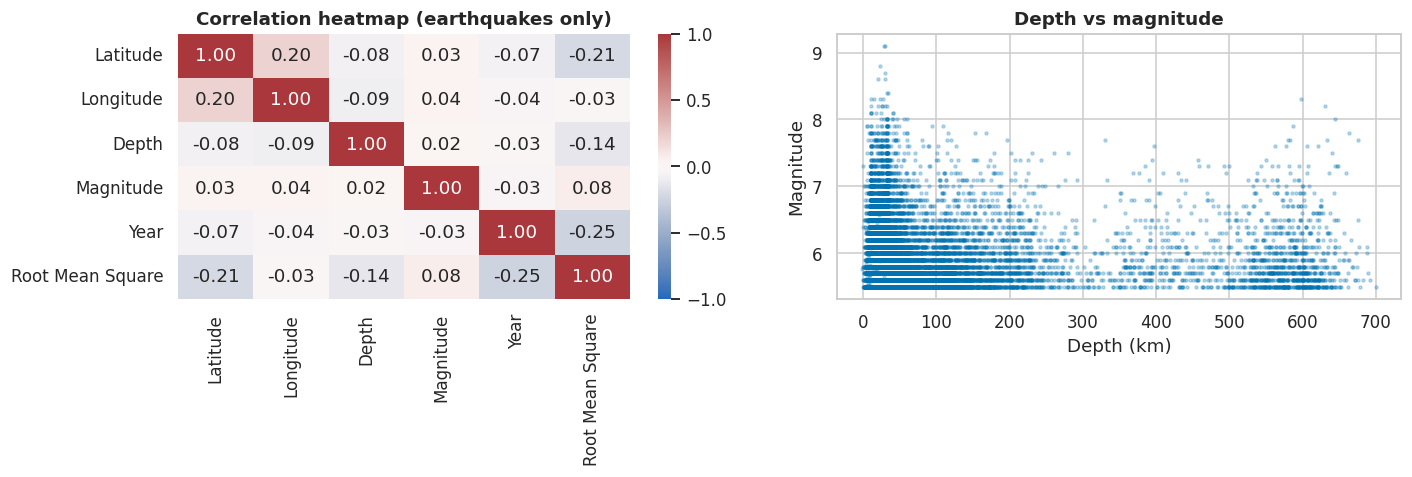

In [15]:
# Correlation between the numeric event descriptors (plus year)
num = raw.loc[raw["Type"] == "Earthquake", ["Latitude", "Longitude", "Depth", "Magnitude", "Year", "Root Mean Square"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation heatmap (earthquakes only)")
axes[1].scatter(quakes_all["Depth"], quakes_all["Magnitude"], s=4, alpha=0.25, color="#0173b2")
axes[1].set_title("Depth vs magnitude"); axes[1].set_xlabel("Depth (km)"); axes[1].set_ylabel("Magnitude")
plt.tight_layout(); plt.show()

**Observation.** Almost nothing is linearly correlated — and that is a finding, not a failure. Depth does not predict
size (r ≈ 0), and latitude/longitude correlations are meaningless as straight lines because seismic belts are curved.
The only notable value is **Year vs Root Mean Square** (a location-fit quality measure), which reflects improving networks,
not geology. **Conclusion for modelling:** the structure here is *spatial and non-linear* — exactly the kind of thing
clustering, not regression, is built to find.

---
# Chapter 6 — When? Myths, clocks and aftershocks

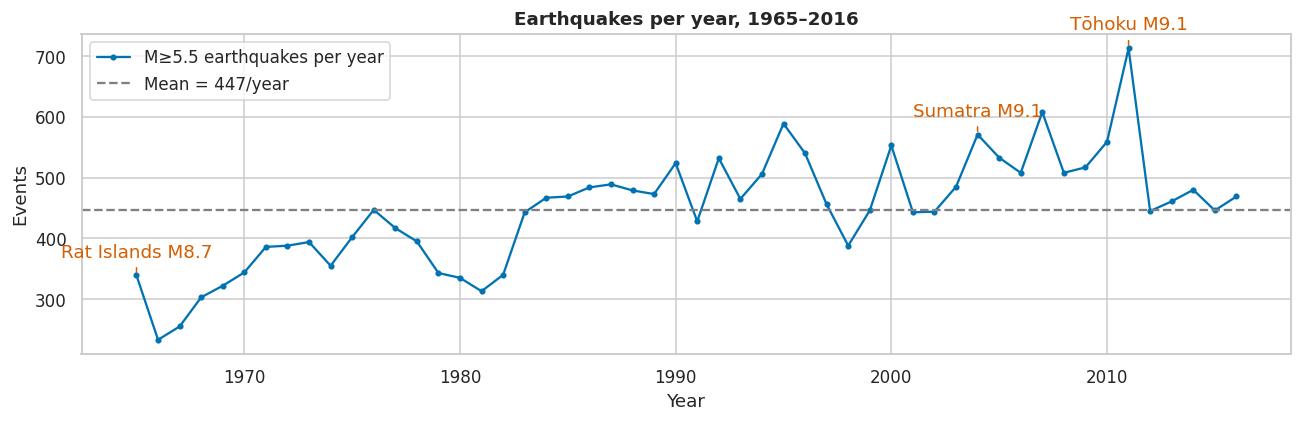

In [16]:
yearly = quakes_all.groupby(quakes_all["Datetime"].dt.year).size()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(yearly.index, yearly.values, marker="o", ms=3, color="#0173b2", label="M≥5.5 earthquakes per year")
ax.axhline(yearly.mean(), ls="--", color="grey", label=f"Mean = {yearly.mean():.0f}/year")
for yr, label in [(2004, "Sumatra M9.1"), (2011, "Tōhoku M9.1"), (1965, "Rat Islands M8.7")]:
    ax.annotate(label, (yr, yearly[yr]), xytext=(0, 12), textcoords="offset points", ha="center",
                arrowprops=dict(arrowstyle="-", color="#d55e00"), color="#d55e00")
ax.set_title("Earthquakes per year, 1965–2016"); ax.set_xlabel("Year"); ax.set_ylabel("Events"); ax.legend()
plt.tight_layout(); plt.show()

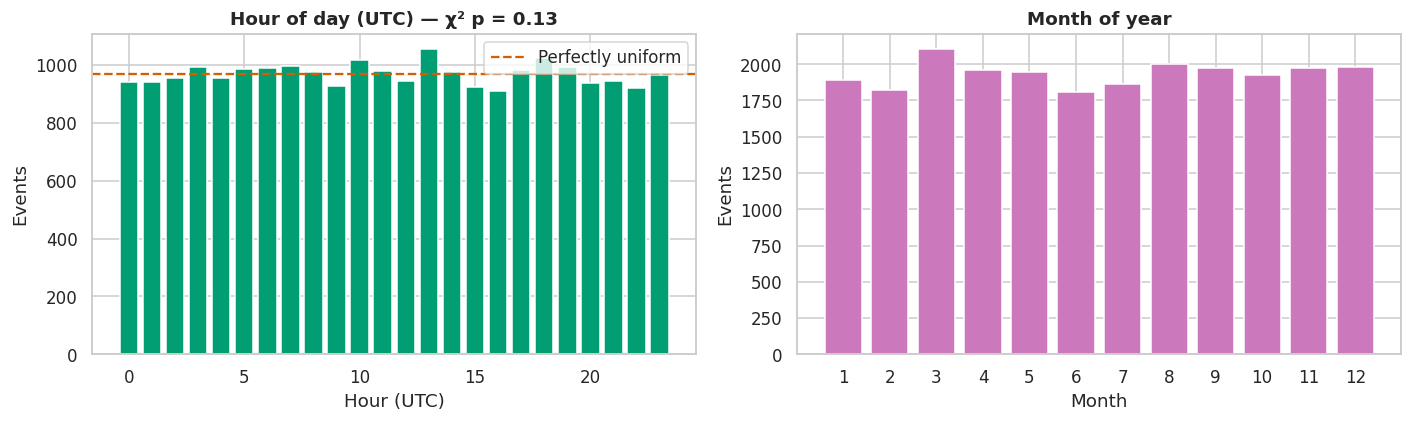

Busiest month overall: 3 | events in March 2011 alone: 228


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hours = quakes_all["Datetime"].dt.hour.value_counts().sort_index()
chi_h = stats.chisquare(hours)
axes[0].bar(hours.index, hours.values, color="#029e73")
axes[0].axhline(hours.mean(), color="#d55e00", ls="--", label="Perfectly uniform")
axes[0].set_title(f"Hour of day (UTC) — χ² p = {chi_h.pvalue:.2f}"); axes[0].set_xlabel("Hour (UTC)"); axes[0].set_ylabel("Events"); axes[0].legend()
months = quakes_all["Datetime"].dt.month.value_counts().sort_index()
axes[1].bar(months.index, months.values, color="#cc78bc")
axes[1].set_title("Month of year"); axes[1].set_xlabel("Month"); axes[1].set_ylabel("Events")
axes[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()
print("Busiest month overall:", months.idxmax(), "| events in March 2011 alone:",
      ((quakes_all["Datetime"].dt.year == 2011) & (quakes_all["Datetime"].dt.month == 3)).sum())

**Observations**

* **No "earthquake hour".** A chi-square test cannot reject a uniform distribution over the 24 hours (p ≈ 0.13 > 0.05).
  The popular idea that quakes favour night or "earthquake weather" finds no support here.
* The yearly count wobbles around ~450, with spikes in **2004–05** and **2011** — the years of the two M9.1 giants.
* **The Earth did not get busier in the 1980s — the network got better.** Counts sit around 300–400 per year until the
  early 1980s and around 450–550 afterwards. A step change like that, right when the quality columns start being filled
  (Chapter 2), is a detection effect: more stations meant fewer M5.5–5.7 events slipped through. A trend in raw counts
  is not automatically a trend in nature.
* **March is the busiest month — but only because of one month in history.** March 2011 alone contributes a few hundred
  events. Big quakes do not respect calendars; they *trigger their own sequences*. The next plot shows how.

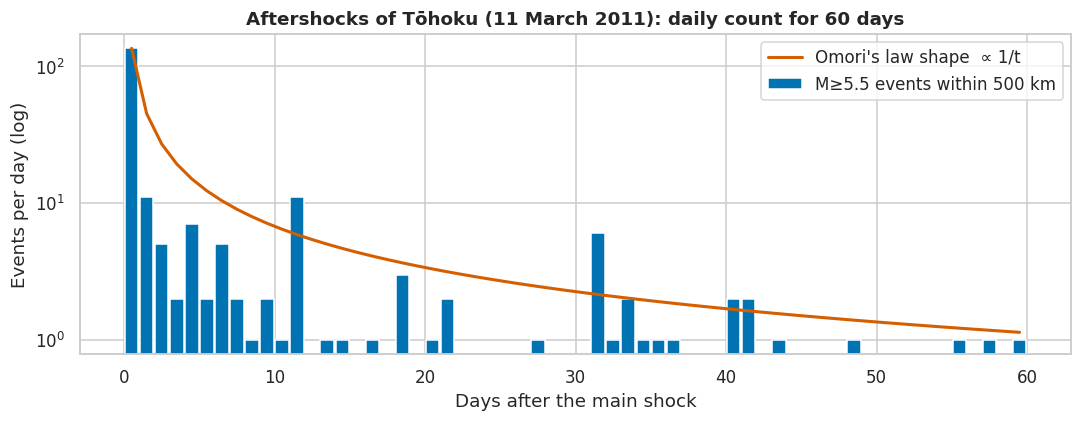

Events within 500 km in the first 24 h: 135, first 30 days: 194


In [18]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between points given in degrees."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

t0 = pd.Timestamp("2011-03-11 05:46:24")
near = haversine_km(38.297, 142.373, quakes_all["Latitude"], quakes_all["Longitude"]) < 500
after = quakes_all[near & (quakes_all["Datetime"] >= t0) & (quakes_all["Datetime"] < t0 + pd.Timedelta(days=60))]
days = ((after["Datetime"] - t0).dt.total_seconds() / 86400).astype(int)
daily = days.value_counts().reindex(range(60), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(daily.index + 0.5, daily.values, width=0.9, color="#0173b2", label="M≥5.5 events within 500 km")
k = daily.iloc[0]
tt = np.arange(0.5, 60)
ax.plot(tt, k * 0.5 / tt, color="#d55e00", lw=2, label="Omori's law shape  ∝ 1/t")
ax.set_yscale("log"); ax.set_title("Aftershocks of Tōhoku (11 March 2011): daily count for 60 days")
ax.set_xlabel("Days after the main shock"); ax.set_ylabel("Events per day (log)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Events within 500 km in the first 24 h: {daily.iloc[0]}, first 30 days: {daily.iloc[:30].sum()}")

**Observation.** In the first 24 hours after Tōhoku, more M≥5.5 quakes struck nearby than in a typical *month* worldwide.
The decay follows **Omori's law** (rate ∝ 1/time). This matters for clustering: points are not independent — aftershock
sequences create dense spatial knots that pull cluster centres toward them. Keep that in mind when reading the results.

---
# Chapter 7 — Not all earthquakes are earthquakes: the Cold War in the catalogue

,tests,first,last,median_depth_km,max_magnitude
Site,,,,,
"Semipalatinsk (USSR, Kazakhstan)",92,1973,1989,0.0,6.30
"Mururoa/Fangataufa (France, Pacific)",28,1977,1991,0.0,6.00
"Novaya Zemlya (USSR, Arctic)",23,1973,1990,0.0,6.90
Nevada Test Site (USA),12,1966,1976,1.2,5.84
Lop Nur (China),10,1983,1996,0.0,6.50
Other,10,1974,1981,0.0,6.00


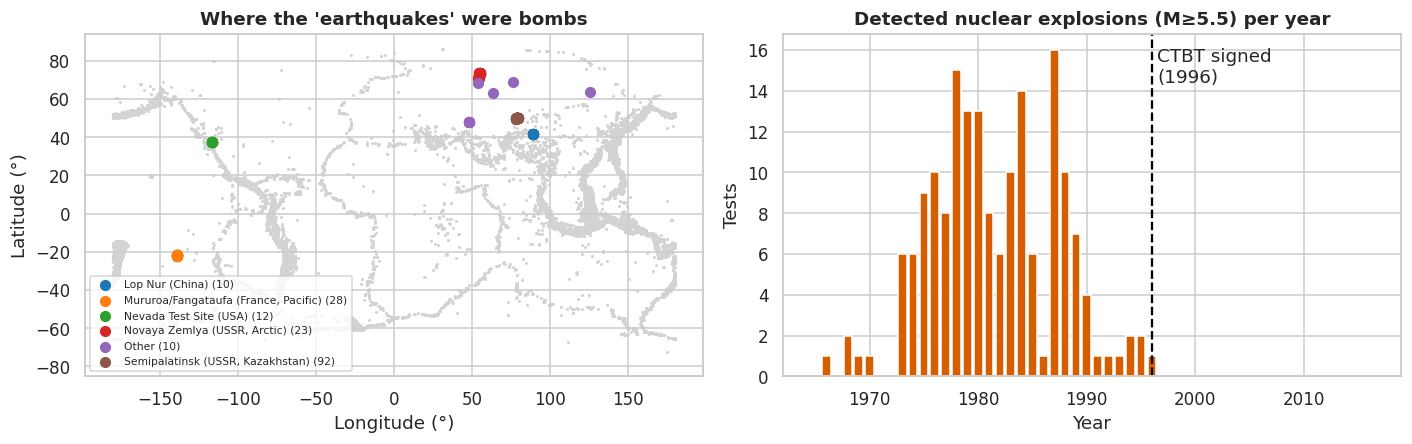

In [19]:
nuc = raw[raw["Type"] == "Nuclear Explosion"].copy()
SITES = {"Semipalatinsk (USSR, Kazakhstan)": (50, 78.5), "Mururoa/Fangataufa (France, Pacific)": (-22, -139),
         "Novaya Zemlya (USSR, Arctic)": (73, 55), "Nevada Test Site (USA)": (37, -116), "Lop Nur (China)": (41.6, 88.5)}
def nearest_site(r, max_km=400):
    d = {k: haversine_km(r["Latitude"], r["Longitude"], *v) for k, v in SITES.items()}
    k = min(d, key=d.get)
    return k if d[k] < max_km else "Other"
nuc["Site"] = nuc.apply(nearest_site, axis=1)
display(nuc.groupby("Site").agg(tests=("ID", "size"), first=("Year", "min"), last=("Year", "max"),
                                median_depth_km=("Depth", "median"), max_magnitude=("Magnitude", "max"))
        .sort_values("tests", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for i, (site, g) in enumerate(nuc.groupby("Site")):
    axes[0].scatter(g["Longitude"], g["Latitude"], s=40, label=f"{site} ({len(g)})", color=CLUSTER_PALETTE[i])
axes[0].scatter(quakes_all["Longitude"], quakes_all["Latitude"], s=1, color="lightgrey", zorder=0)
axes[0].set_title("Where the 'earthquakes' were bombs"); axes[0].set_xlabel("Longitude (°)"); axes[0].set_ylabel("Latitude (°)")
axes[0].legend(fontsize=7, loc="lower left")
yr = nuc["Year"].value_counts().reindex(range(1965, 2017), fill_value=0)
axes[1].bar(yr.index, yr.values, color="#d55e00")
axes[1].axvline(1996, color="black", ls="--"); axes[1].text(1996.5, yr.max() * 0.9, "CTBT signed\n(1996)")
axes[1].set_title("Detected nuclear explosions (M≥5.5) per year"); axes[1].set_xlabel("Year"); axes[1].set_ylabel("Tests")
plt.tight_layout(); plt.show()

**Observations**

* **175 underground nuclear tests were strong enough to be logged as M≥5.5 seismic events** — the global seismic
  network was, in effect, a Cold-War monitoring system. Seismology is still how test bans are verified today.
* Over half come from **Semipalatinsk** in Kazakhstan, followed by France's **Mururoa** atoll in the Pacific.
* Their signatures are different from earthquakes: **depth ≈ 0 km**, and locations in *otherwise silent places*
  (Kazakh steppe, Nevada desert) or isolated atolls.
* The 10 **"Other"** events are scattered across Russia and Central Asia, away from the main test sites, all between 1974
  and 1981. Their pattern is consistent with the Soviet *"Peaceful Nuclear Explosions"* programme (explosions for
  mining, reservoirs and deep seismic sounding) — worth checking against historical lists before stating it as fact.
* The record **ends in 1996**, the year the Comprehensive Nuclear-Test-Ban Treaty was opened for signature.

**Modelling decision:** these events are human-made, so we **exclude them from training** (they would create artificial
clusters at test sites). But we keep them aside for a test in Chapter 14: *will a model that has only ever seen natural
earthquakes recognise a bomb as "abnormal"?*

---
# Chapter 8 — Preparing the data for clustering
## 8.1 Cleaning decisions (each one justified)

| Issue found | Decision | Why |
|---|---|---|
| 3 rows with ISO-format dates | Parsed with a second format (done in Ch. 2) | Keeps all events; no information lost |
| Quality columns 69–99 % missing | **Dropped from features**, rows kept | Missingness is historical (Ch. 2); imputing would invent measurements |
| 180 non-earthquake events | **Removed from training**, kept aside for Ch. 14 | Human-made; would form artificial clusters |
| 3 slightly negative depths (≈ −1 km) | Clipped to 0 | Events located above sea level (on mountains); needed for `log1p` |
| Exact duplicates | None found (checked) | — |
| Depth/magnitude "outliers" | Checked with IQR, **kept** | Deep and giant quakes are real physics, not errors |

In [20]:
quakes = raw[raw["Type"] == "Earthquake"].copy()
non_quakes = raw[raw["Type"] != "Earthquake"].copy()
print("Earthquakes kept for modelling:", len(quakes), "| non-earthquakes set aside:", len(non_quakes))

print("Negative depths:", (quakes["Depth"] < 0).sum())
quakes["Depth"] = quakes["Depth"].clip(lower=0)
non_quakes["Depth"] = non_quakes["Depth"].clip(lower=0)
print("Duplicate rows:", quakes.duplicated().sum(),
      "| duplicate (time, place) events:", quakes.duplicated(["Datetime", "Latitude", "Longitude"]).sum())

Earthquakes kept for modelling: 23232 | non-earthquakes set aside: 180
Negative depths: 3
Duplicate rows: 0 | duplicate (time, place) events: 0


,feature,lower_fence,upper_fence,outliers,outliers_%
0,Depth,-44.7,114.5,3239,13.9
1,Magnitude,5.0,6.6,1471,6.3


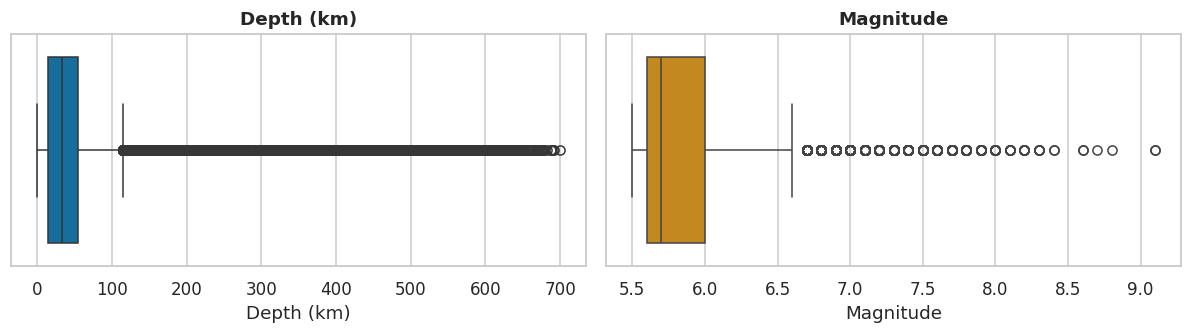

In [21]:
def iqr_outlier_report(df, cols):
    """Count values outside 1.5×IQR fences for each column (report only, no removal)."""
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        out = ((df[c] < lo) | (df[c] > hi)).sum()
        rows.append({"feature": c, "lower_fence": round(lo, 2), "upper_fence": round(hi, 2),
                     "outliers": out, "outliers_%": round(out / len(df) * 100, 1)})
    return pd.DataFrame(rows)

display(iqr_outlier_report(quakes, ["Depth", "Magnitude"]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
sns.boxplot(x=quakes["Depth"], ax=axes[0], color="#0173b2"); axes[0].set_title("Depth (km)"); axes[0].set_xlabel("Depth (km)")
sns.boxplot(x=quakes["Magnitude"], ax=axes[1], color="#de8f05"); axes[1].set_title("Magnitude"); axes[1].set_xlabel("Magnitude")
plt.tight_layout(); plt.show()

**Why we keep the "outliers".** IQR flags about **one in seven** events as depth outliers (everything below ~115 km —
essentially the deeper half of the intermediate class and *every deep quake*), and every quake above M6.6 as a magnitude
outlier. Removing them would delete the Tonga slab, every M7+ quake and the 2013 Okhotsk event: the most
scientifically interesting part of the data. An outlier rule designed for bell-shaped data is the wrong tool for a
physically multi-modal variable. Instead of deleting, we **transform** depth (next section).

## 8.2 Feature engineering — the date-line problem and why latitude/longitude cannot be used directly

K-Means and Ward linkage measure **Euclidean distance**. Raw longitude breaks that: the map has a seam at ±180°.
Two earthquakes in Fiji at 179.9°E and 179.9°W are ~20 km apart on Earth but **359.8 "units" apart** in raw longitude.
Chapter 3 showed that one of the most active regions on the planet sits *exactly on that seam*.

**Engineered features**

1. **3-D Cartesian coordinates on the unit sphere** — `x = cos(lat)·cos(lon)`, `y = cos(lat)·sin(lon)`, `z = sin(lat)`.
   Every point on Earth becomes a point in 3-D; the seam disappears and straight-line distance now grows with true
   great-circle distance.
2. **`log_depth = log(1 + depth)`** — compresses the long right tail (skewness drops from about 3.3 to 0.8), treats
   10 km vs 33 km as a small difference (they are both "shallow, uncertain"), and keeps 100 km vs 600 km clearly apart.

**Why these should improve the clusters:** the model can now group a regime that straddles the date line, and depth can
separate stacked regimes (a shallow arc above a deep slab) that would otherwise overlap on a map.
Magnitude is **not** a feature: it is measured on mixed scales (Ch. 2) and, as Chapter 5 showed, size is not tied to
place in a simple way — we use it to *describe* regimes afterwards.

In [22]:
def add_geo_features(df):
    """Add unit-sphere Cartesian coordinates and log-depth. Works for any frame with Latitude/Longitude/Depth."""
    out = df.copy()
    lat, lon = np.radians(out["Latitude"]), np.radians(out["Longitude"])
    out["x"] = np.cos(lat) * np.cos(lon)
    out["y"] = np.cos(lat) * np.sin(lon)
    out["z"] = np.sin(lat)
    out["log_depth"] = np.log1p(out["Depth"].clip(lower=0))
    return out

FEATURES = ["x", "y", "z", "log_depth"]
quakes = add_geo_features(quakes)
non_quakes = add_geo_features(non_quakes)

# Demonstration of the date-line problem
demo = add_geo_features(pd.DataFrame({"Latitude": [-17.0, -17.0], "Longitude": [179.9, -179.9], "Depth": [500, 500]}))
print("Raw lat/lon Euclidean distance       :", round(np.linalg.norm(demo[["Latitude", "Longitude"]].diff().iloc[1]), 1), "degrees")
print("3-D Cartesian distance (unit sphere) :", round(np.linalg.norm(demo[["x", "y", "z"]].diff().iloc[1]), 5),
      "→ ×6371 =", round(np.linalg.norm(demo[["x", "y", "z"]].diff().iloc[1]) * 6371, 1), "km")
print("True great-circle distance           :", round(haversine_km(-17, 179.9, -17, -179.9), 1), "km")
display(quakes[FEATURES].describe().T.round(3))

Raw lat/lon Euclidean distance       : 359.8 degrees
3-D Cartesian distance (unit sphere) : 0.00334 → ×6371 = 21.3 km
True great-circle distance           : 21.3 km


,count,mean,std,min,25%,50%,75%,max
x,23232.0,-0.403,0.503,-0.997,-0.849,-0.582,-0.062,0.996
y,23232.0,0.171,0.580,-1.000,-0.113,0.255,0.662,1.000
z,23232.0,0.019,0.468,-0.975,-0.321,-0.064,0.422,0.998
log_depth,23232.0,3.584,1.048,0.000,2.773,3.526,4.022,6.553


## 8.3 Train/test split and leakage-safe scaling
Clustering has no target, but we still hold out **20 %** of events (guideline 7.2). This lets us check whether the
regimes found on 80 % of history **generalise** to events the model never saw — i.e. whether they are real structure
rather than memorised noise. `StandardScaler` is **fitted on the training split only** and then applied to both
splits (guideline 7.1).

In [23]:
train_df, test_df = train_test_split(quakes, test_size=0.2, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(train_df[FEATURES])          # fitted on TRAIN only
X_train = scaler.transform(train_df[FEATURES])
X_test = scaler.transform(test_df[FEATURES])
X_nuc = scaler.transform(non_quakes[FEATURES])
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train means after scaling ≈ 0:", X_train.mean(axis=0).round(3))
print("Test means (not exactly 0 — expected, the scaler never saw them):", X_test.mean(axis=0).round(3))

Train: (18585, 4) | Test: (4647, 4)
Train means after scaling ≈ 0: [-0. -0.  0. -0.]
Test means (not exactly 0 — expected, the scaler never saw them): [-0.014  0.012  0.01  -0.007]


## 8.4 Evaluation helper
* **Silhouette** (−1…1, higher = better): how much closer a point is to its own cluster than to the next one.
* **Davies–Bouldin** (≥ 0, lower = better): average similarity between each cluster and its most similar neighbour.
* **Calinski–Harabasz** (higher = better): between-cluster dispersion ÷ within-cluster dispersion.

Silhouette needs all pairwise distances (≈ 18,600² ≈ 346 million pairs), so we compute it on a fixed random sample of
10,000 points — a standard, reproducible approximation.

In [24]:
def cluster_metrics(X, labels, name, split):
    """Return the three mandatory internal clustering metrics as a dict."""
    return {"Algorithm": name, "Split": split, "n_clusters": len(np.unique(labels)),
            "Silhouette (↑)": silhouette_score(X, labels, sample_size=min(10000, len(X)), random_state=RANDOM_STATE),
            "Davies-Bouldin (↓)": davies_bouldin_score(X, labels),
            "Calinski-Harabasz (↑)": calinski_harabasz_score(X, labels)}

---
# Chapter 9 — Algorithm 1: K-Means
## 9.1 Choosing k: the Elbow curve, backed up by three metrics
K-Means minimises **inertia** (sum of squared distances to the nearest centre). Inertia always falls as k grows, so we
look for the "elbow" where extra clusters stop paying off — and cross-check with silhouette, DB and CH.

In [25]:
k_range = range(2, 16)
scan = []
for k in k_range:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train)
    m = cluster_metrics(X_train, km_k.labels_, "K-Means", "train")
    m["k"], m["Inertia"] = k, km_k.inertia_
    scan.append(m)
scan = pd.DataFrame(scan).set_index("k")
display(scan[["Inertia", "Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]].round(3))

,Inertia,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
k,,,,
2,51774.648,0.367,1.316,8099.260
3,39637.699,0.314,1.235,8134.197
4,32262.937,0.321,1.116,8077.736
5,27608.973,0.346,1.070,7862.228
6,23735.418,0.343,0.974,7922.241
7,20737.437,0.349,1.003,8003.524
8,18455.737,0.354,0.962,8035.990
9,16775.398,0.361,0.954,7967.931
10,15466.030,0.358,0.970,7856.535


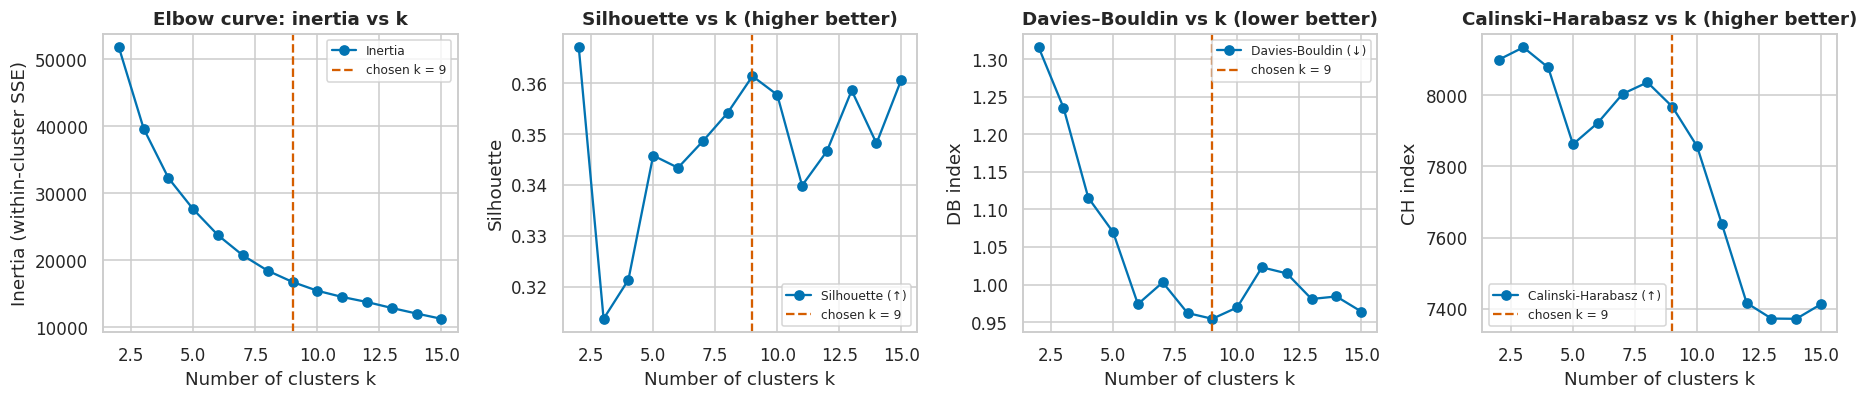

In [26]:
CHOSEN_K = 9
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
specs = [("Inertia", "Elbow curve: inertia vs k", "Inertia (within-cluster SSE)"),
         ("Silhouette (↑)", "Silhouette vs k (higher better)", "Silhouette"),
         ("Davies-Bouldin (↓)", "Davies–Bouldin vs k (lower better)", "DB index"),
         ("Calinski-Harabasz (↑)", "Calinski–Harabasz vs k (higher better)", "CH index")]
for ax, (col, title, ylab) in zip(axes, specs):
    ax.plot(scan.index, scan[col], marker="o", color="#0173b2", label=col)
    ax.axvline(CHOSEN_K, color="#d55e00", ls="--", label=f"chosen k = {CHOSEN_K}")
    ax.set_title(title); ax.set_xlabel("Number of clusters k"); ax.set_ylabel(ylab); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation — why k = 9.**
The elbow is *gradual* (common for real geographic data — the Earth does not come in perfectly separate blobs), with the
steepest gains up to about k = 6 and diminishing returns after ~9. On its own the elbow is ambiguous, so we let the
other metrics break the tie: **Davies–Bouldin reaches its lowest value at k = 9**, and silhouette is at its best for any
k ≥ 3 at k = 9 (k = 2 scores marginally higher, but simply cuts the planet into two halves — too coarse to say anything).
Calinski–Harabasz is fairly flat (≈ 7,400–8,100) and mildly favours small k, as it often does.

The deciding argument is physical, not just numerical: k = 8 → 9 is the step where the single "deep" cluster splits into
two: the **Tonga–Fiji deep slab** (median depth ≈ 360 km) and a separate **intermediate-depth slab** regime (≈ 150 km)
under the western Pacific and Asia. A clustering that separates
a 600-km-deep slab from the shallow arc above it is capturing real geology.

## 9.2 Final K-Means model and naming the regimes
Cluster numbers from K-Means are arbitrary (and can permute between library versions). To keep the story stable we name
clusters **automatically**: each cluster centre is converted back to latitude/longitude/depth and matched to the
nearest reference region with the Hungarian algorithm (one name per cluster). The reference list is just a set of
coordinates we chose after looking at the maps in Chapter 3 — the algorithm never sees it.

In [27]:
kmeans = KMeans(n_clusters=CHOSEN_K, n_init=10, random_state=RANDOM_STATE).fit(X_train)
km_train, km_test = kmeans.labels_, kmeans.predict(X_test)

REGION_ANCHORS = {   # name: (lat, lon, typical depth km) — used ONLY for naming, never for fitting
    "N. Pacific arc: Japan–Kuril–Aleutians": (45, 145, 33),
    "Indonesia–Philippines arc (shallow)": (2, 124, 33),
    "SW Pacific arcs: PNG–Vanuatu–Tonga (shallow)": (-15, 160, 33),
    "Tonga–Fiji deep slab": (-20, -178, 360),
    "W. Pacific & Asia intermediate-depth slabs": (5, 128, 150),
    "Americas north of the equator & N. Atlantic": (13, -89, 12),
    "Alpine–Himalayan belt, Africa & Arctic–Indian ridges": (35, 47, 12),
    "Andes subduction (S. America)": (-23, -71, 80),
    "Southern Ocean ridges & Scotia arc": (-53, -26, 10),
}

def centre_to_geo(centres_scaled, scaler):
    """Convert scaled cluster centres back to lat/lon/depth."""
    c = scaler.inverse_transform(centres_scaled)
    xyz = c[:, :3] / np.linalg.norm(c[:, :3], axis=1, keepdims=True)
    lat = np.degrees(np.arcsin(xyz[:, 2])); lon = np.degrees(np.arctan2(xyz[:, 1], xyz[:, 0]))
    return pd.DataFrame({"lat": lat, "lon": lon, "depth_km": np.expm1(c[:, 3])})

def name_clusters(centres_scaled, scaler, anchors=REGION_ANCHORS):
    """Assign each cluster a unique region name by minimum (distance + depth) cost matching."""
    geo = centre_to_geo(centres_scaled, scaler)
    names = list(anchors)
    cost = np.zeros((len(geo), len(names)))
    for j, n in enumerate(names):
        a_lat, a_lon, a_dep = anchors[n]
        cost[:, j] = haversine_km(geo["lat"], geo["lon"], a_lat, a_lon) + 8 * np.abs(np.log1p(geo["depth_km"]) - np.log1p(a_dep)) * 300
    r, c = linear_sum_assignment(cost)
    mapping = {int(i): names[j] for i, j in zip(r, c)}
    return mapping, geo

SHORT = {"N. Pacific arc: Japan–Kuril–Aleutians": "N. Pacific arc", "Indonesia–Philippines arc (shallow)": "Indo-Philippines",
         "SW Pacific arcs: PNG–Vanuatu–Tonga (shallow)": "SW Pacific arcs", "Tonga–Fiji deep slab": "Tonga deep slab",
         "W. Pacific & Asia intermediate-depth slabs": "Intermediate slabs", "Americas north of the equator & N. Atlantic": "N. Americas & Atl.",
         "Alpine–Himalayan belt, Africa & Arctic–Indian ridges": "Alpine–Himalayan", "Andes subduction (S. America)": "Andes",
         "Southern Ocean ridges & Scotia arc": "Southern Ocean"}   # short labels for crowded plots

km_names, km_centres_geo = name_clusters(kmeans.cluster_centers_, scaler)
km_centres_geo["name"] = km_centres_geo.index.map(km_names)
display(km_centres_geo.round(1))
# Note: a centre is an *average* position. For a belt that wraps around Antarctica (the Southern Ocean ridges) the average
# of the 3-D points lies near the South Pole, even though no earthquake happens there — a nice illustration that a
# centroid need not be a real data point.

,lat,lon,depth_km,name
0,-17.3,168.6,27.1,SW Pacific arcs: PNG–Vanuatu–Tonga (shallow)
1,5.1,120.1,27.8,Indonesia–Philippines arc (shallow)
2,-20.0,177.4,300.5,Tonga–Fiji deep slab
3,13.9,-87.5,16.5,Americas north of the equator & N. Atlantic
4,12.6,128.6,181.8,W. Pacific & Asia intermediate-depth slabs
5,33.4,44.2,15.7,"Alpine–Himalayan belt, Africa & Arctic–Indian ..."
6,-75.8,-66.9,12.6,Southern Ocean ridges & Scotia arc
7,-22.0,-70.0,77.5,Andes subduction (S. America)
8,47.5,156.5,29.1,N. Pacific arc: Japan–Kuril–Aleutians


---
# Chapter 10 — Algorithm 2: Agglomerative (hierarchical) clustering
Agglomerative clustering starts with every point as its own cluster and repeatedly merges the closest pair. It needs a
full distance matrix — for 18,600 points that is ~1.4 GB of memory and O(n²) time, too heavy for a laptop. We therefore
fit it on a **reproducible random sample of 6,000 training events** (32 % of the training set), then extend the labels
to every remaining point with a **k-nearest-neighbour classifier** trained on the sample's cluster labels. Agglomerative
clustering has no `.predict()`, so this KNN step is also how test events and the GUI get a hierarchical label.

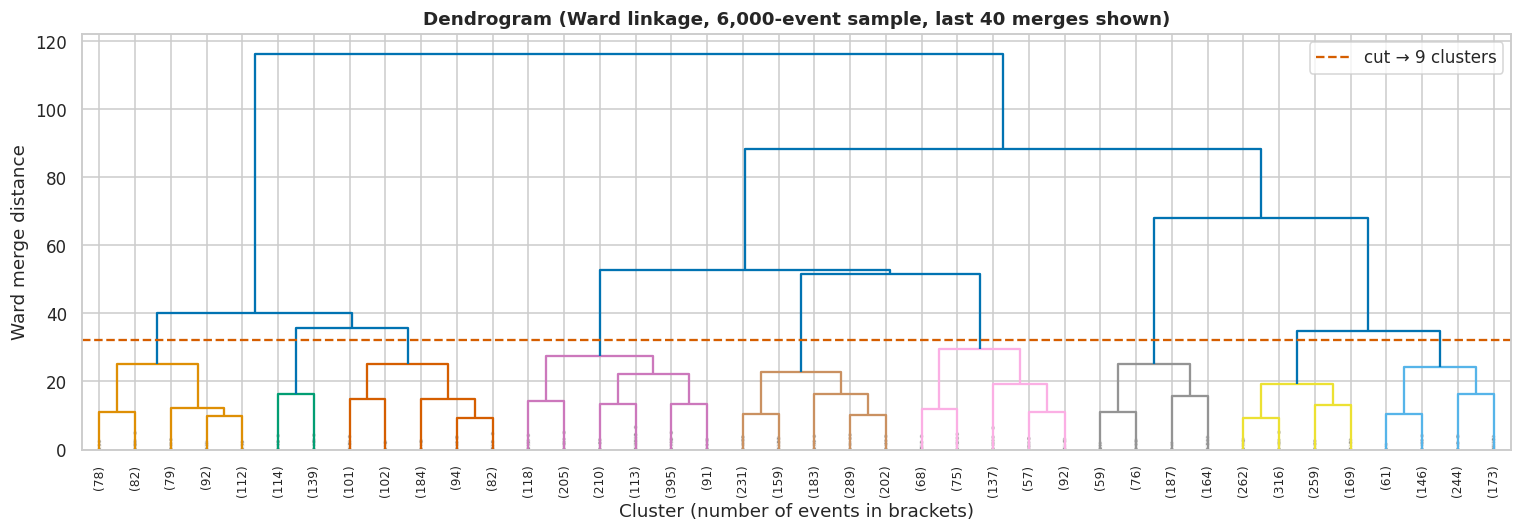

,k_clusters,merge_height_above,merge_height_below,vertical_gap
0,2,116.41,88.48,27.93
1,3,88.48,67.99,20.49
2,4,67.99,52.76,15.23
3,5,52.76,51.59,1.18
4,6,51.59,40.09,11.50
5,7,40.09,35.77,4.32
6,8,35.77,34.73,1.04
7,9,34.73,29.40,5.32
8,10,29.40,27.47,1.93
9,11,27.47,25.23,2.24


In [28]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(len(X_train), size=6000, replace=False)
X_sample = X_train[sample_idx]

# 10.1 Dendrogram (Ward linkage)
Z = linkage(X_sample, method="ward")
cut_height = (Z[-CHOSEN_K, 2] + Z[-CHOSEN_K + 1, 2]) / 2      # height that yields exactly CHOSEN_K clusters
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=40, leaf_rotation=90, leaf_font_size=8, show_contracted=True,
           color_threshold=cut_height, ax=ax)
ax.axhline(cut_height, color="#d55e00", ls="--", label=f"cut → {CHOSEN_K} clusters")
ax.set_title("Dendrogram (Ward linkage, 6,000-event sample, last 40 merges shown)")
ax.set_xlabel("Cluster (number of events in brackets)"); ax.set_ylabel("Ward merge distance"); ax.legend()
plt.tight_layout(); plt.show()

# Gap in merge height that "protects" a k-cluster solution: height(merge k→k-1) − height(merge k+1→k)
H = Z[:, 2]
gaps = pd.DataFrame({"k_clusters": range(2, 13),
                     "merge_height_above": [H[-(k - 1)] for k in range(2, 13)],
                     "merge_height_below": [H[-k] for k in range(2, 13)]})
gaps["vertical_gap"] = gaps["merge_height_above"] - gaps["merge_height_below"]
display(gaps.round(2))

**Observation.** The tallest vertical gaps are at the very top (k = 2–4): the data first splits into a few
super-regions. Below that the gaps shrink, but not smoothly: **k = 6 and k = 9 are local peaks** in the gap table
(≈ 11.5 and ≈ 5.3), while k = 5, 8 and 10 are protected by almost nothing (≈ 1–2). So the dendrogram *independently*
supports a cut at 9 clusters — the same k the K-Means metrics pointed to — and lets us compare the two algorithms like
for like.

In [29]:
# 10.2 Comparing linkage strategies on the same sample
linkage_rows = []
linkage_labels = {}
for method in ["ward", "complete", "average", "single"]:
    agg = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage=method).fit(X_sample)
    linkage_labels[method] = agg.labels_
    m = cluster_metrics(X_sample, agg.labels_, f"Agglomerative ({method})", "sample")
    sizes = np.sort(np.bincount(agg.labels_))[::-1]
    m["largest_cluster_%"] = sizes[0] / len(X_sample) * 100
    m["smallest_cluster"] = sizes[-1]
    m["cluster_sizes"] = list(sizes)
    linkage_rows.append(m)
linkage_table = pd.DataFrame(linkage_rows).drop(columns=["Split"])
display(linkage_table.round(3))

,Algorithm,n_clusters,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),largest_cluster_%,smallest_cluster,cluster_sizes
0,Agglomerative (ward),9,0.302,1.105,2158.218,18.867,253,"[1132, 1064, 1006, 624, 563, 486, 443, 429, 253]"
1,Agglomerative (complete),9,0.238,1.163,1547.689,31.400,81,"[1884, 990, 787, 668, 666, 525, 235, 164, 81]"
2,Agglomerative (average),9,0.239,1.022,1116.847,57.533,2,"[3452, 630, 546, 520, 426, 268, 147, 9, 2]"
3,Agglomerative (single),9,-0.100,0.688,3.342,99.783,1,"[5987, 6, 1, 1, 1, 1, 1, 1, 1]"


**Observation — linkage matters enormously.**
* **Ward** gives balanced, compact clusters and the best metrics — it minimises within-cluster variance, the same
  objective as K-Means, so it suits our data.
* **Complete** linkage (merge by the *farthest* pair) produces uneven groups and a noticeably lower silhouette.
* **Average** linkage leaves a few tiny clusters of just a handful of points while one cluster swallows most of the data.
* **Single** linkage (merge by the *nearest* pair) collapses into **one giant cluster plus single-point "clusters"** —
  the classic *chaining* effect: along a continuous seismic belt there is always a near neighbour, so single linkage
  walks around the Ring of Fire and joins everything.

**Final choice: Ward linkage, 9 clusters.**

Agreement of KNN with the true agglomerative labels on the sample itself: 99.02 %


,lat,lon,depth_km,name,share_of_dominant_regime_%
0,22.9,53.0,20.8,"A0 ≈ Alpine–Himalayan belt, Africa & Arctic–In...",72.3
1,46.3,147.9,26.8,A1 ≈ N. Pacific arc: Japan–Kuril–Aleutians,78.7
2,17.3,-74.9,14.6,A2 ≈ Americas north of the equator & N. Atlantic,84.6
3,-12.2,167.3,341.6,A3 ≈ Tonga–Fiji deep slab,75.1
4,-30.4,168.0,11.3,A4 ≈ SW Pacific arcs: PNG–Vanuatu–Tonga (shallow),59.2
5,3.3,121.0,43.1,A5 ≈ Indonesia–Philippines arc (shallow),79.3
6,-40.4,-68.1,21.6,A6 ≈ Southern Ocean ridges & Scotia arc,49.5
7,-8.0,-76.7,128.4,A7 ≈ Andes subduction (S. America),82.8
8,-15.0,166.0,40.1,A8 ≈ SW Pacific arcs: PNG–Vanuatu–Tonga (shallow),92.0


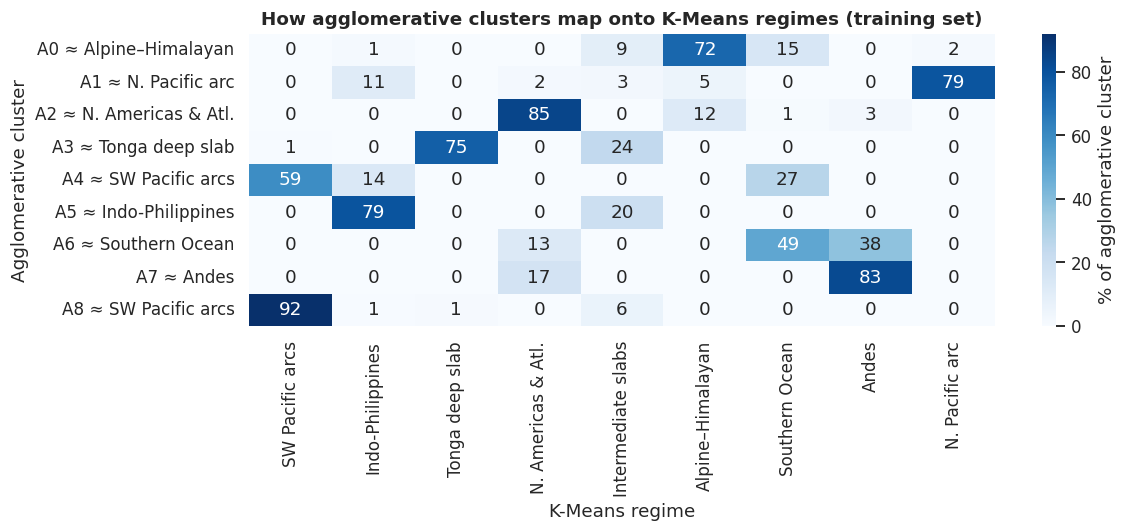

In [30]:
# 10.3 Final agglomerative model and label propagation
agglo = AgglomerativeClustering(n_clusters=CHOSEN_K, linkage="ward").fit(X_sample)
agglo_knn = KNeighborsClassifier(n_neighbors=15).fit(X_sample, agglo.labels_)
ag_train, ag_test = agglo_knn.predict(X_train), agglo_knn.predict(X_test)
print("Agreement of KNN with the true agglomerative labels on the sample itself:",
      round((agglo_knn.predict(X_sample) == agglo.labels_).mean() * 100, 2), "%")

# Name each agglomerative cluster after the K-Means regime it overlaps most (prefix "A<n>" keeps names unique,
# because two agglomerative clusters can share the same dominant K-Means regime).
overlap = pd.crosstab(ag_train, km_train)
ag_names = {int(c): f"A{c} ≈ {km_names[int(overlap.loc[c].idxmax())]}" for c in overlap.index}
ag_short = {int(c): f"A{c} ≈ {SHORT[km_names[int(overlap.loc[c].idxmax())]]}" for c in overlap.index}
ag_centres = np.vstack([X_train[ag_train == c].mean(axis=0) for c in range(CHOSEN_K)])
ag_centres_geo = centre_to_geo(ag_centres, scaler)
ag_centres_geo["name"] = ag_centres_geo.index.map(ag_names)
ag_centres_geo["share_of_dominant_regime_%"] = (overlap.max(axis=1) / overlap.sum(axis=1) * 100).values
display(ag_centres_geo.round(1))

fig, ax = plt.subplots(figsize=(11, 5))
ov = overlap.copy(); ov.index = [ag_short[i] for i in ov.index]; ov.columns = [SHORT[km_names[c]] for c in ov.columns]
sns.heatmap(ov.div(ov.sum(axis=1), axis=0) * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of agglomerative cluster"}, ax=ax)
ax.set_title("How agglomerative clusters map onto K-Means regimes (training set)")
ax.set_xlabel("K-Means regime"); ax.set_ylabel("Agglomerative cluster")
plt.tight_layout(); plt.show()

**Observation — the two algorithms carve the Earth slightly differently.** Most agglomerative clusters correspond to
one K-Means regime. The interesting disagreement: Ward linkage **splits the large SW Pacific region in two** (north and
south — A4 and A8), and in exchange it has **no separate intermediate-depth cluster**: those 70–300 km events are absorbed
partly into the deep Tonga cluster (A3) and partly into the Indonesia–Philippines arc (A5). Ward also merges the southern
Andes with the Southern Ocean (A6). K-Means, by contrast, decided depth was worth a cluster of its own. Both are defensible;
the metrics in Chapter 11 tell us which is more compact.

---
# Chapter 11 — Evaluation: both algorithms, both splits

In [31]:
results = pd.DataFrame([
    cluster_metrics(X_train, km_train, "K-Means (k=9)", "train"),
    cluster_metrics(X_test, km_test, "K-Means (k=9)", "test"),
    cluster_metrics(X_train, ag_train, "Agglomerative Ward (k=9)", "train"),
    cluster_metrics(X_test, ag_test, "Agglomerative Ward (k=9)", "test"),
])
display(results.round(3))

ari_km_ag = adjusted_rand_score(km_test, ag_test)
nmi_km_ag = normalized_mutual_info_score(km_test, ag_test)
print(f"Agreement between K-Means and Agglomerative on the test set: ARI = {ari_km_ag:.3f}, NMI = {nmi_km_ag:.3f}")

# Stability: does K-Means find the same regimes with different random initialisations?
stab = [adjusted_rand_score(km_train, KMeans(CHOSEN_K, n_init=10, random_state=s).fit_predict(X_train)) for s in range(5)]
print("K-Means stability across 5 other seeds (ARI vs seed 42):", np.round(stab, 3))

,Algorithm,Split,n_clusters,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
0,K-Means (k=9),train,9,0.361,0.954,7967.931
1,K-Means (k=9),test,9,0.359,0.962,1971.892
2,Agglomerative Ward (k=9),train,9,0.303,1.106,6574.485
3,Agglomerative Ward (k=9),test,9,0.298,1.112,1631.217


Agreement between K-Means and Agglomerative on the test set: ARI = 0.608, NMI = 0.691


K-Means stability across 5 other seeds (ARI vs seed 42): [0.993 0.838 0.998 1.    0.999]


**Observations**

* **K-Means scores better on all three metrics.** (Compare Calinski–Harabasz only *within* a split: CH grows with the
  number of points, so the smaller test split always has a smaller CH.) That is partly by design: all three metrics reward compact, roughly
  spherical clusters — exactly what K-Means optimises. Agglomerative-Ward is somewhat behind but in the same range.
* **Train and test scores are almost identical** for both algorithms. The regimes found on 80 % of history describe
  unseen events equally well — the structure is real, not over-fitted.
* A silhouette around **0.36** is "moderate". That is honest for this data: seismic belts are continuous lines that
  touch each other (e.g. the Philippines arc runs into Japan's), so boundary points inevitably sit between clusters.
* The two algorithms broadly agree (ARI printed above) — they draw most of the same regimes, differing mainly in where
  long continuous belts are cut (see the heatmap in Ch. 10.3).
* **Stability:** four of five other random seeds give practically the same K-Means partition (ARI ≥ 0.99); one lands in a
  different local optimum (ARI ≈ 0.84). That is exactly why we run `n_init = 10` restarts and keep the best.

---
# Chapter 12 — Seeing the clusters
## 12.1 PCA (2 principal components) — mandatory for every algorithm
PCA is fitted on the **training** features only and used purely for drawing.

Variance explained by PC1, PC2: [0.362 0.285] → total 64.7 %


,x,y,z,log_depth
PC1,0.626,-0.620,-0.259,-0.397
PC2,0.290,0.329,0.726,-0.529


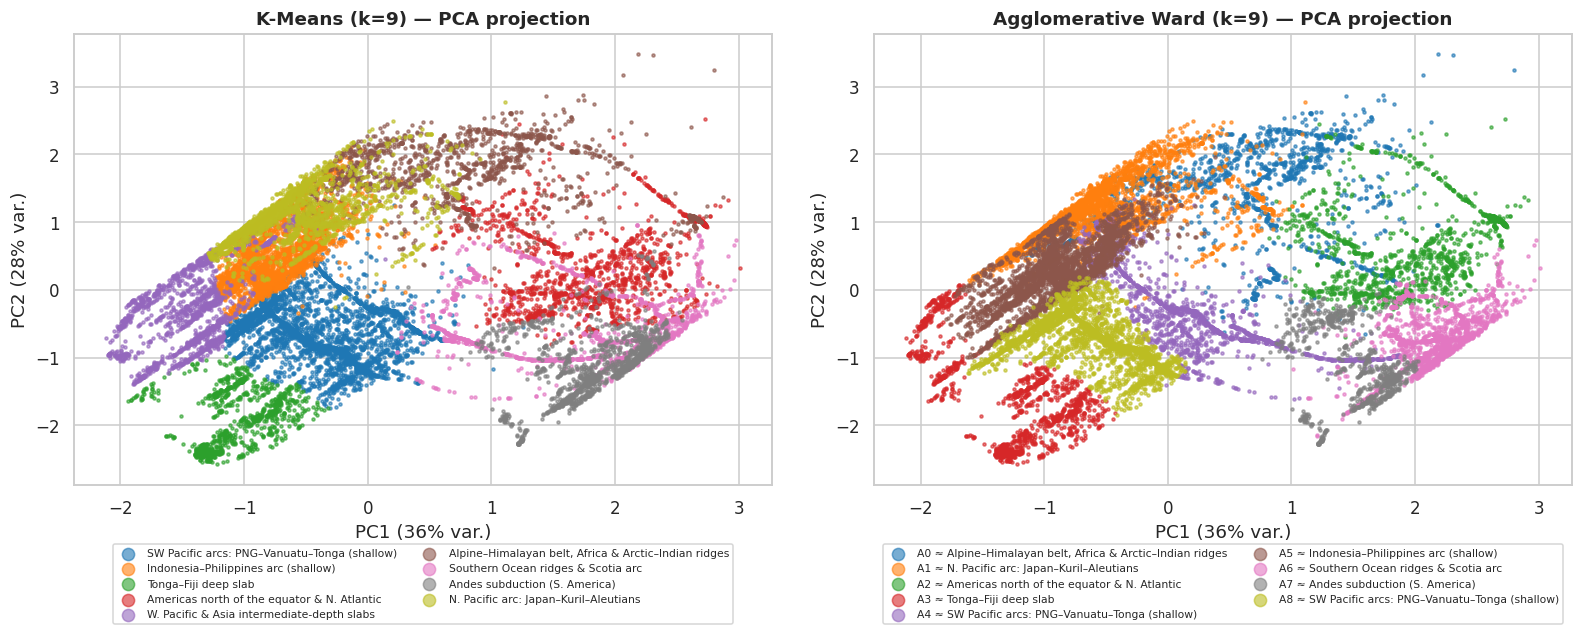

In [32]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train)
P_train = pca.transform(X_train)
ev = pca.explained_variance_ratio_
print("Variance explained by PC1, PC2:", ev.round(3), "→ total", round(ev.sum() * 100, 1), "%")
display(pd.DataFrame(pca.components_, columns=FEATURES, index=["PC1", "PC2"]).round(3))

def scatter_clusters(ax, XY, labels, names, title, xlabel, ylabel, s=4):
    for c in np.unique(labels):
        mask = labels == c
        ax.scatter(XY[mask, 0], XY[mask, 1], s=s, alpha=0.6, color=CLUSTER_PALETTE[c % 10], label=names[c])
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
scatter_clusters(axes[0], P_train, km_train, km_names, "K-Means (k=9) — PCA projection",
                 f"PC1 ({ev[0]*100:.0f}% var.)", f"PC2 ({ev[1]*100:.0f}% var.)")
scatter_clusters(axes[1], P_train, ag_train, ag_names, "Agglomerative Ward (k=9) — PCA projection",
                 f"PC1 ({ev[0]*100:.0f}% var.)", f"PC2 ({ev[1]*100:.0f}% var.)")
for ax in axes:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, markerscale=4, fontsize=7)
plt.tight_layout(); plt.show()

**Observation.** Two components keep only part of the variance (printed above) — the third geographic direction is
flattened — so some regimes overlap in this view even though they are far apart on the globe. Still, the main
separations are visible, and the loadings show what the axes mean: **PC1** contrasts x against y (east–west position)
with some depth, **PC2** is mostly z (north–south) with depth again. Depth loads on *both* axes. The **deep Tonga slab** and the **intermediate-depth slabs** sit apart from the shallow belts
along the depth-loaded direction. PCA is a linear "shadow" of 4-D data; the world map in 12.3 is the more faithful view.

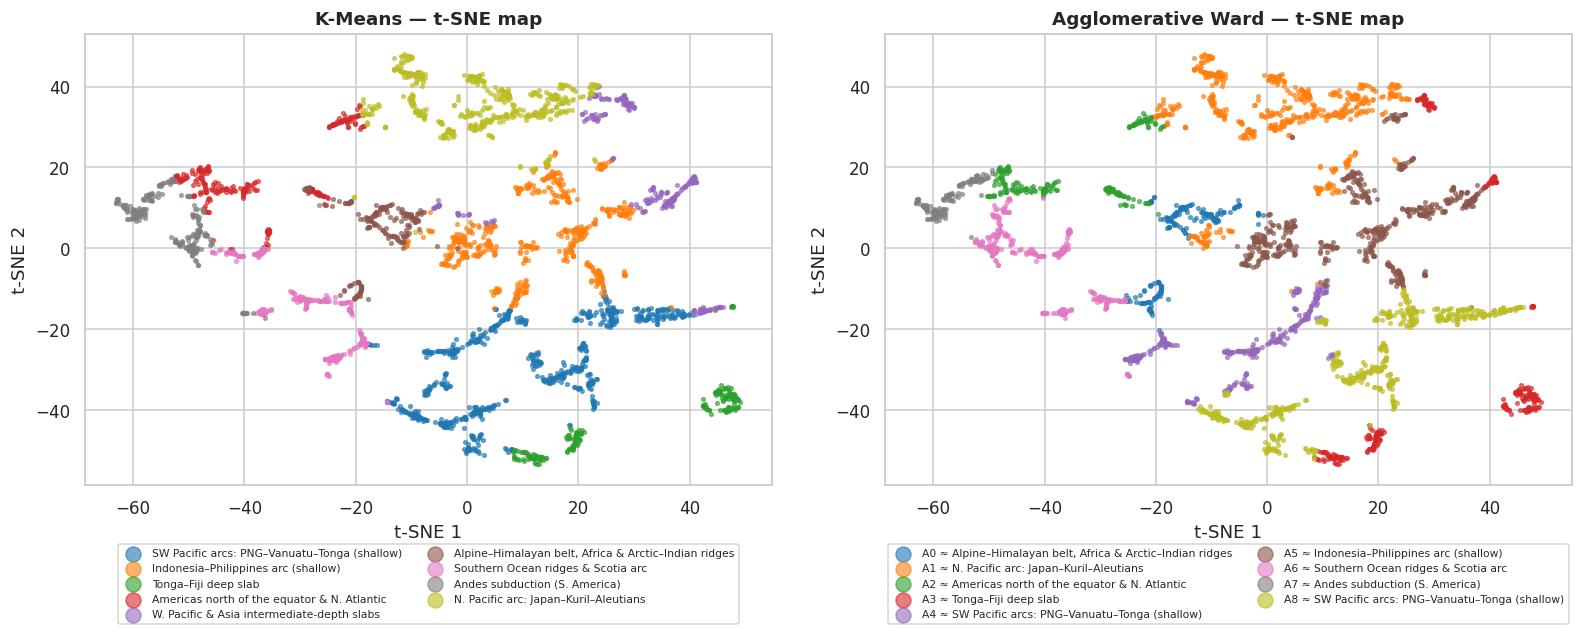

In [33]:
# 12.2 t-SNE (encouraged) for both algorithms on a 3,000-point training sample
tsne_idx = rng.choice(len(X_train), size=3000, replace=False)
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=RANDOM_STATE).fit_transform(X_train[tsne_idx])
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
scatter_clusters(axes[0], T, km_train[tsne_idx], km_names, "K-Means — t-SNE map", "t-SNE 1", "t-SNE 2", s=6)
scatter_clusters(axes[1], T, ag_train[tsne_idx], ag_names, "Agglomerative Ward — t-SNE map", "t-SNE 1", "t-SNE 2", s=6)
for ax in axes:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, markerscale=4, fontsize=7)
plt.tight_layout(); plt.show()

**Observation.** t-SNE preserves *local* neighbourhoods, so it shows what PCA could not: most regimes form their own
coherent islands, and the islands are elongated — they are belts, not blobs. Several islands contain internal
"strings" which are individual arcs and aftershock knots. Distances *between* islands in t-SNE are not meaningful,
so we do not read anything into how far apart two islands are.

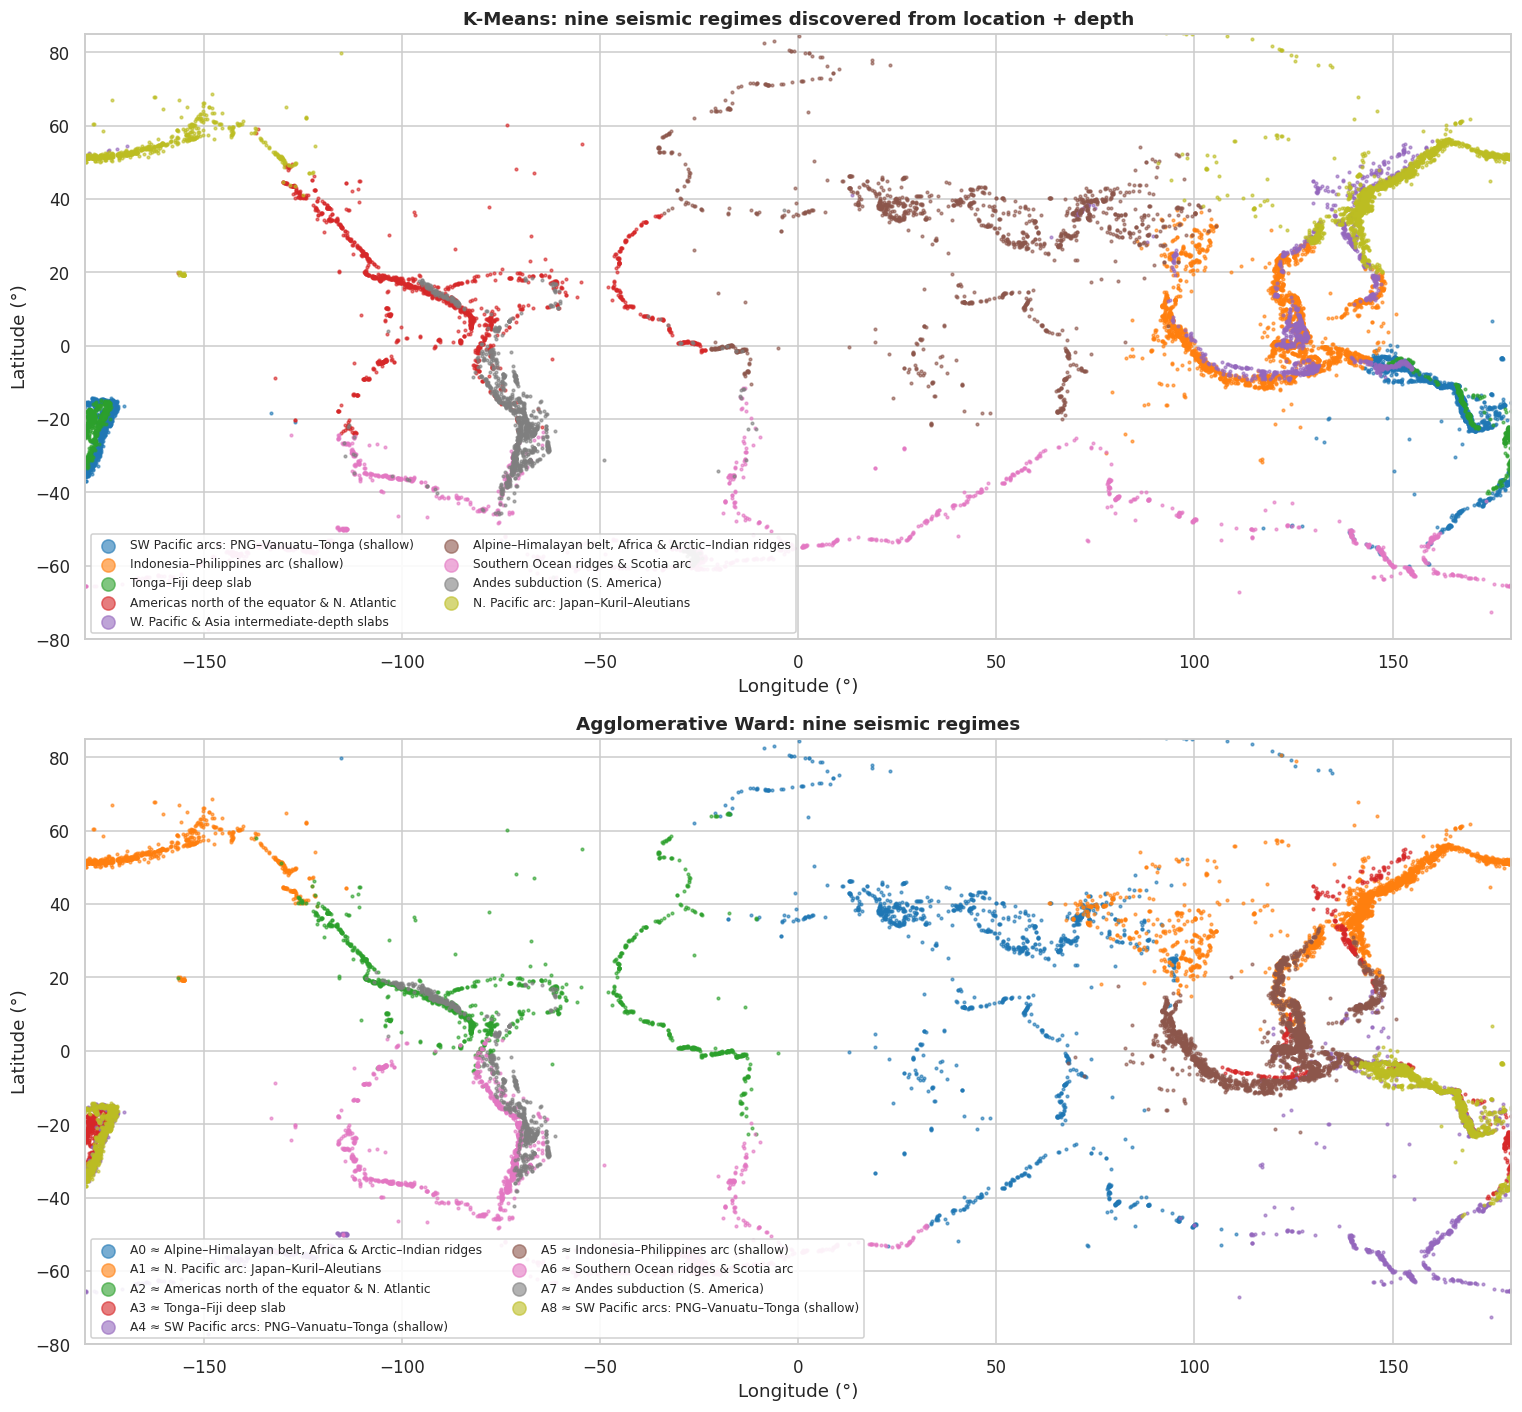

In [34]:
# 12.3 The clusters on the world map
fig, axes = plt.subplots(2, 1, figsize=(14, 13))
for ax, labels, names, title in [(axes[0], km_train, km_names, "K-Means: nine seismic regimes discovered from location + depth"),
                                 (axes[1], ag_train, ag_names, "Agglomerative Ward: nine seismic regimes")]:
    scatter_clusters(ax, train_df[["Longitude", "Latitude"]].values, labels, names, title, "Longitude (°)", "Latitude (°)", s=3)
    ax.set_xlim(-180, 180); ax.set_ylim(-80, 85)
    ax.legend(loc="lower left", fontsize=8, markerscale=5, ncol=2, framealpha=0.9)
plt.tight_layout(); plt.show()

**Observation — the machine has drawn the tectonic map.**
Without any geology, the clusters line up with named tectonic systems: the **Japan–Kuril–Aleutian arc**, the
**Indonesia–Philippines arc**, the **Andes**, the **Alpine–Himalayan belt**, the **Southern Ocean ridges**. Two details
stand out:

1. **The Tonga–Fiji cluster crosses the ±180° line without a break.** With raw longitude this would have been split into
   two clusters at opposite ends of the map. The 3-D feature engineering is visibly doing its job.
2. **Some clusters are defined by depth, not place.** The intermediate-depth cluster overlaps Indonesia, the Philippines
   and the Hindu Kush on the map, yet is separate because those events happen 70–300 km down, inside sinking slabs —
   the same places on the surface, a different physical regime underneath.
3. **Not every cluster is one tectonic system.** The brown regime joins the Alpine–Himalayan collision belt with the
   Indian Ocean ridges and the Atlantic–Arctic ridge north of ~40°N (Iceland included). With only position and depth, the
   model cannot tell a collision zone from a spreading ridge — both are shallow and far from the Pacific. Adding
   focal-mechanism data (how the fault moved) would be the way to separate them.

---
# Chapter 13 — What the clusters mean: profiles of the nine regimes

In [35]:
train_df = train_df.assign(KMeans=km_train, Regime=pd.Series(km_train, index=train_df.index).map(km_names),
                           Agglo=ag_train)

def b_value(mags, mmin=5.5, mmax=7.5):
    """Least-squares Gutenberg–Richter b-value on the cumulative counts."""
    M = np.round(np.arange(mmin, mmax + 0.01, 0.1), 1)
    N = np.array([(mags >= m - 1e-9).sum() for m in M])
    keep = N > 0
    return -np.polyfit(M[keep], np.log10(N[keep]), 1)[0]

profile = train_df.groupby("Regime").agg(
    events=("ID", "size"),
    median_depth_km=("Depth", "median"),
    deep_share_pct=("Depth", lambda s: (s > 300).mean() * 100),
    mean_magnitude=("Magnitude", "mean"),
    M7plus_per_1000=("Magnitude", lambda s: (s >= 7).mean() * 1000),
    largest=("Magnitude", "max"),
    b_value=("Magnitude", b_value),
).sort_values("events", ascending=False)
profile["share_pct"] = profile["events"] / profile["events"].sum() * 100
display(profile.round(2))

,events,median_depth_km,deep_share_pct,mean_magnitude,M7plus_per_1000,largest,b_value,share_pct
Regime,,,,,,,,
SW Pacific arcs: PNG–Vanuatu–Tonga (shallow),3922,33.00,0.00,5.89,31.87,8.1,1.03,21.10
Indonesia–Philippines arc (shallow),3340,33.00,0.00,5.88,30.84,8.6,0.98,17.97
N. Pacific arc: Japan–Kuril–Aleutians,2867,33.00,0.00,5.89,32.44,9.1,0.99,15.43
Southern Ocean ridges & Scotia arc,1595,10.00,0.00,5.84,18.81,8.2,1.23,8.58
Americas north of the equator & N. Atlantic,1544,12.00,0.00,5.89,33.68,8.0,0.99,8.31
W. Pacific & Asia intermediate-depth slabs,1454,151.55,24.69,5.89,36.45,8.3,0.95,7.82
Andes subduction (S. America),1353,80.00,5.91,5.91,40.65,8.8,0.91,7.28
"Alpine–Himalayan belt, Africa & Arctic–Indian ridges",1317,11.90,0.00,5.88,30.37,7.9,1.06,7.09
Tonga–Fiji deep slab,1193,362.70,52.72,5.88,33.53,7.8,1.06,6.42


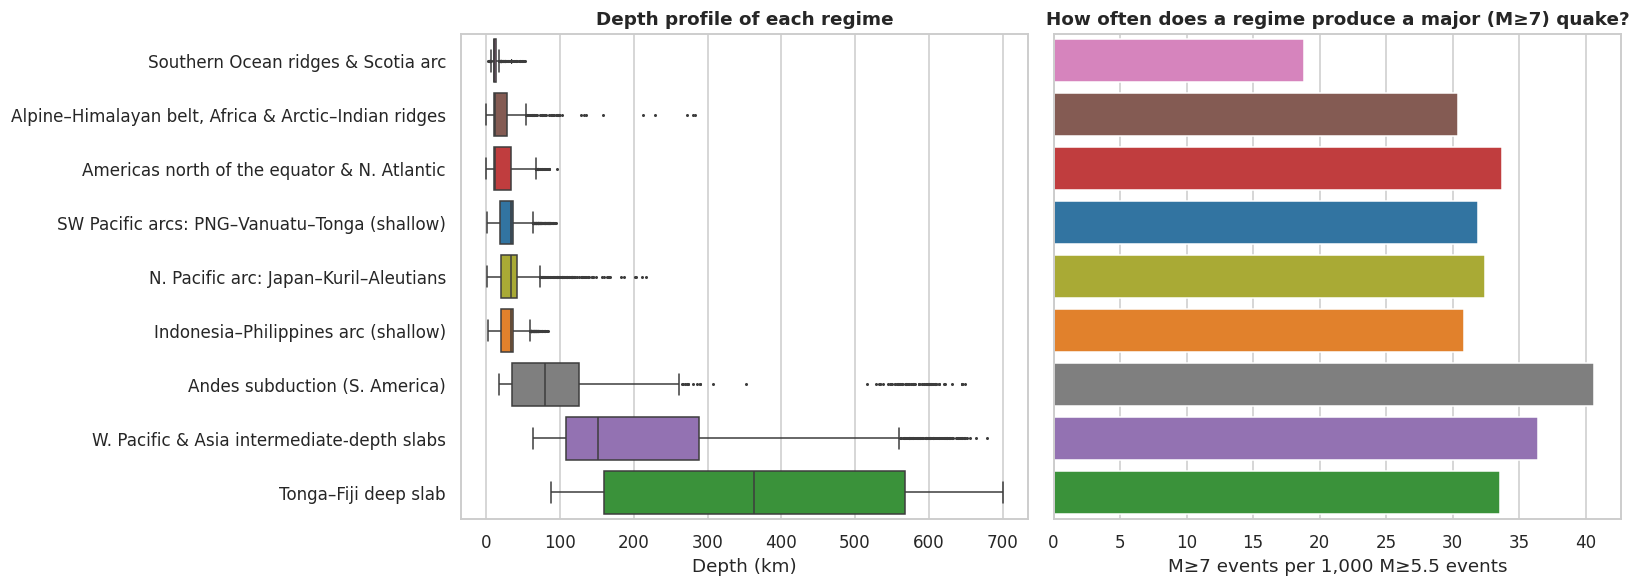

In [36]:
order = list(profile.sort_values("median_depth_km").index)
regime_colour = {name: CLUSTER_PALETTE[c] for c, name in km_names.items()}   # same colours as the maps
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
sns.boxplot(data=train_df, y="Regime", x="Depth", order=order, hue="Regime", palette=regime_colour,
            legend=False, ax=axes[0], fliersize=1)
axes[0].set_title("Depth profile of each regime"); axes[0].set_xlabel("Depth (km)"); axes[0].set_ylabel("")
p2 = profile.loc[order].reset_index()
sns.barplot(data=p2, y="Regime", x="M7plus_per_1000", order=order, hue="Regime", palette=regime_colour,
            legend=False, ax=axes[1])
axes[1].set_title("How often does a regime produce a major (M≥7) quake?")
axes[1].set_xlabel("M≥7 events per 1,000 M≥5.5 events"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Stories of the nine regimes** (numbers from the tables above)

* **The Pacific dominates.** The three shallow Pacific arcs (SW Pacific, Indonesia–Philippines, N. Pacific) alone hold
  more than half of all M≥5.5 earthquakes.
* **Tonga–Fiji is the deepest place on Earth that still breaks.** Its median depth is ~360 km and about half its events are
  below 300 km. The Pacific plate here is old, cold and sinking fast, so it stays brittle deep into the mantle.
* **The Andes regime is a "middle-depth" system** (median ≈ 80 km) — the Nazca plate dips under South America at a
  shallower angle than the Pacific under Tonga, exactly as the cross-section in Chapter 4 showed.
* **The Southern Ocean ridge regime is the "quiet giant".** It is shallow (≈ 10 km), has the *lowest* mean magnitude and the
  fewest M≥7 events. Plates pulling apart at ridges break in many small slips, not huge locked ruptures — and its higher
  b-value says the same thing numerically: relatively *more* small quakes per big one.
* **Size is surprisingly uniform elsewhere.** Mean magnitude differs by only a few hundredths between most regimes, and
  every shallow subduction regime has produced an M8+ in these 52 years. Danger is not confined to one region; any active margin can host a giant.
  That is why we did not use magnitude to *define* the clusters — it would have added noise rather than structure.
* **Per-regime b-values cluster around 1**, the global law, but with real variation. Seismologists use exactly this
  variation to compare the stress state of different regions — our clusters give a natural, data-driven way to group
  them.

* **The Andes is the most "big-quake-prone" regime:** the highest M≥7 rate (≈ 41 per 1,000 events) and the lowest
  b-value (≈ 0.91) — relatively *fewer* small quakes for every large one. Chile's 2010 M8.8 is no coincidence.

*(The magnitude statistics depend on the mixed magnitude scales noted in Chapter 2; differences of a few hundredths should
not be over-interpreted.)*

---
# Chapter 14 — Validation after the fact (labels used only now)
## 14.1 Do the clusters respect the seismological depth classes?
The depth classes (shallow < 70 km, intermediate 70–300 km, deep > 300 km) are a standard seismological labelling.
They were **never given to the model** — but log-depth was, so we check how cleanly the regimes separate them.

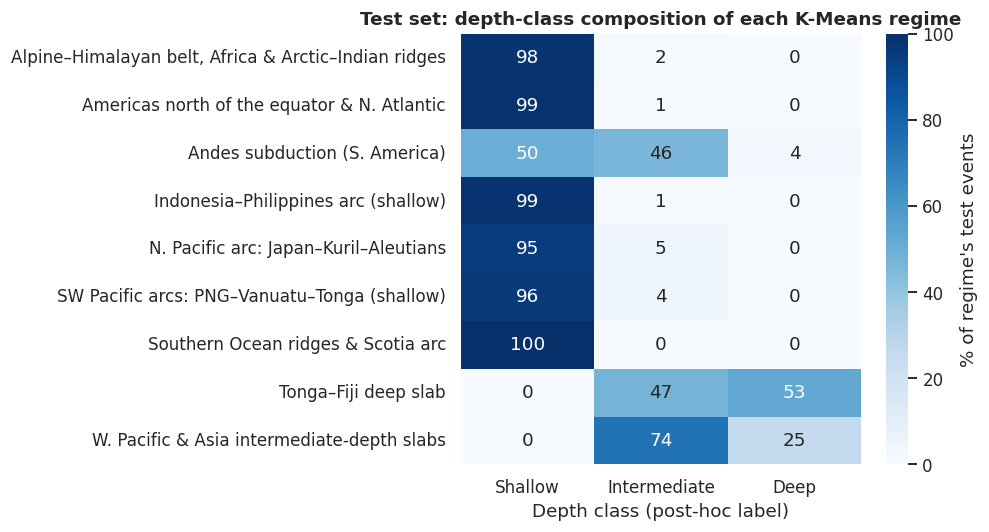

Purity: share of test events in their regime's majority depth class: 89.6 %
NMI between regimes and depth class: 0.281


In [37]:
test_df = test_df.assign(KMeans=km_test, Regime=pd.Series(km_test, index=test_df.index).map(km_names),
                         DepthClass=pd.cut(test_df["Depth"], [-1, 70, 300, 800], labels=["Shallow", "Intermediate", "Deep"]))
ct = pd.crosstab(test_df["Regime"], test_df["DepthClass"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(ct.round(1), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of regime's test events"}, ax=ax)
ax.set_title("Test set: depth-class composition of each K-Means regime"); ax.set_xlabel("Depth class (post-hoc label)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Purity: share of test events in their regime's majority depth class:",
      round(pd.crosstab(test_df["Regime"], test_df["DepthClass"]).max(axis=1).sum() / len(test_df) * 100, 1), "%")
print("NMI between regimes and depth class:", round(normalized_mutual_info_score(test_df["DepthClass"], km_test), 3))

**Observation.** Most regimes are almost entirely one depth class; the slab regimes are the ones where intermediate and
deep events concentrate. NMI with depth class is modest — and should be, because each regime also encodes *geography*
(nine regions vs three depth bands). The clusters are geography × depth, not a re-discovery of depth alone.

## 14.2 Can a model trained only on natural earthquakes recognise a nuclear bomb?
Idea: for every event, compute its distance to the nearest K-Means centre. Natural earthquakes lie *on* the seismic
belts the model learned; a bomb in the Kazakh steppe should lie far from all of them. We set a threshold at the
**95th percentile of test-earthquake distances** (so by construction 5 % of real earthquakes are flagged) and see what
fraction of the 180 non-earthquake events cross it.

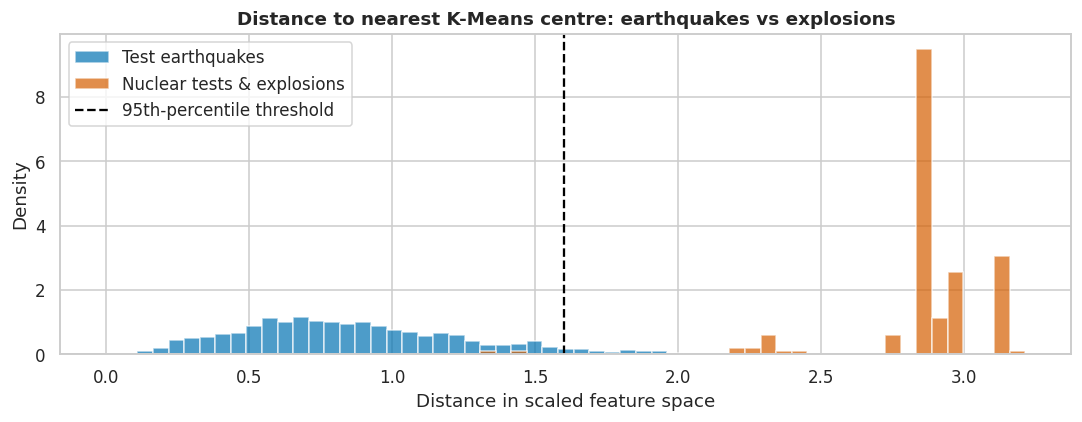

Flagged as anomalous: 98.9% of explosions vs 5.0% of earthquakes (by design)


,events,flagged_pct,median_distance
Site,,,
"Semipalatinsk (USSR, Kazakhstan)",93,100.0,2.9
"Mururoa/Fangataufa (France, Pacific)",30,100.0,3.1
"Novaya Zemlya (USSR, Arctic)",24,100.0,3.0
Nevada Test Site (USA),12,91.7,2.3
Other,11,100.0,2.8
Lop Nur (China),10,90.0,2.9


In [38]:
d_test = kmeans.transform(X_test).min(axis=1)
d_nuc = kmeans.transform(X_nuc).min(axis=1)
threshold = np.quantile(d_test, 0.95)
non_quakes = non_quakes.assign(distance=d_nuc, flagged=d_nuc > threshold)
non_quakes["Site"] = non_quakes.apply(nearest_site, axis=1)

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, max(d_test.max(), d_nuc.max()), 60)
ax.hist(d_test, bins=bins, alpha=0.7, density=True, label="Test earthquakes", color="#0173b2")
ax.hist(d_nuc, bins=bins, alpha=0.7, density=True, label="Nuclear tests & explosions", color="#d55e00")
ax.axvline(threshold, color="black", ls="--", label="95th-percentile threshold")
ax.set_title("Distance to nearest K-Means centre: earthquakes vs explosions")
ax.set_xlabel("Distance in scaled feature space"); ax.set_ylabel("Density"); ax.legend()
plt.tight_layout(); plt.show()

print(f"Flagged as anomalous: {non_quakes['flagged'].mean()*100:.1f}% of explosions vs 5.0% of earthquakes (by design)")
display(non_quakes.groupby("Site").agg(events=("ID", "size"), flagged_pct=("flagged", lambda s: s.mean() * 100),
                                       median_distance=("distance", "median")).round(1).sort_values("events", ascending=False))

**Observation.** The explosions sit far to the right of the earthquakes — a model that has **never seen a single bomb**
flags about **99 % of them** as abnormal (versus 5 % of real earthquakes), using nothing but location and depth. Even
Mururoa, an atoll in the Pacific, is caught: its *depth of ~0 km* is unlike any natural Pacific quake. The few misses are
at Nevada and Lop Nur, which sit near genuinely active crust. Real test-ban monitoring adds waveform features for that reason — but as a by-product of
clustering, this is a remarkable result, and it is the idea behind the **"Is this event typical?"** check in our GUI.

**An honest caveat (expect this in the viva).** Most of the separation comes from **depth**: 93 % of the explosions are recorded at ≤ 1 km, while only 17 of 23,232 natural earthquakes (0.07 %) are that shallow. So the model is really saying *"nothing natural this size happens this close to the surface, here"*. Location still matters — it is what catches the few explosions with non-zero depth — but we should not claim the clusters detect bombs from geography alone.

---
# Chapter 15 — Saving models and artefacts for the GUI
The Streamlit app (`app/app.py`) loads these files so it uses *exactly* the models evaluated above.

In [39]:
train_df_out = train_df.assign(split="train")
test_df_out = test_df.assign(split="test", Agglo=ag_test)
catalogue = pd.concat([train_df_out, test_df_out])
catalogue["AggloRegime"] = catalogue["Agglo"].map(ag_names)

joblib.dump(scaler, f"{MODEL_DIR}/scaler.pkl")
joblib.dump(kmeans, f"{MODEL_DIR}/kmeans.pkl")
joblib.dump(agglo_knn, f"{MODEL_DIR}/agglo_knn.pkl")
meta = {
    "features": FEATURES, "k": CHOSEN_K,
    "kmeans_names": {str(k): v for k, v in km_names.items()},
    "agglo_names": {str(k): v for k, v in ag_names.items()},
    "anomaly_threshold": float(threshold),
    "test_distance_quantiles": np.quantile(d_test, np.linspace(0, 1, 101)).tolist(),
    "metrics": results.round(4).to_dict(orient="records"),
    "elbow": scan.reset_index()[["k", "Inertia", "Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]].round(4).to_dict(orient="list"),
    "linkage_table": linkage_table.drop(columns=["cluster_sizes"]).round(4).to_dict(orient="records"),
    "ari_kmeans_vs_agglo": float(ari_km_ag),
    "explosion_flag_rate": float(non_quakes["flagged"].mean()),
}
with open(f"{MODEL_DIR}/meta.json", "w") as f:
    json.dump(meta, f, indent=2)
catalogue[["Datetime", "Latitude", "Longitude", "Depth", "Magnitude", "Magnitude Type", "KMeans", "Regime",
           "Agglo", "AggloRegime", "split"]].to_csv(f"{MODEL_DIR}/clustered_catalogue.csv", index=False)
print("Saved:", sorted(os.listdir(MODEL_DIR)))

Saved: ['agglo_knn.pkl', 'clustered_catalogue.csv', 'kmeans.pkl', 'meta.json', 'scaler.pkl']


---
# Chapter 16 — Conclusion
## 16.1 Final comparison table

In [40]:
summary = results.pivot(index="Algorithm", columns="Split",
                        values=["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]).round(3)
display(summary)

Silhouette (↑)        Davies-Bouldin (↓)         \
Split                              test  train               test  train   
Algorithm                                                                  
Agglomerative Ward (k=9)          0.298  0.303              1.112  1.106   
K-Means (k=9)                     0.359  0.361              0.962  0.954   

                         Calinski-Harabasz (↑)            
Split                                     test     train  
Algorithm                                                 
Agglomerative Ward (k=9)              1631.217  6574.485  
K-Means (k=9)                         1971.892  7967.931

## 16.2 What did we learn?

**Answer to our question.** Yes — given only *where* and *how deep*, both algorithms rediscovered the major tectonic
systems of the planet, including a regime (Tonga–Fiji deep slab) that is defined by what happens hundreds of kilometres
underground, and one (the Southern Ocean ridges) that behaves differently in size, not just in place.

**Which algorithm, and why.**
**K-Means** is our final model: it scores best on Silhouette, Davies–Bouldin and Calinski–Harabasz, generalises to the test
split with essentially no drop, is stable across random seeds, scales to the full catalogue, and has a native
`.predict()` (plus distances to centres) — which is what powers the GUI and the anomaly test. **Agglomerative-Ward** is a
close second and is valuable for *understanding*: its dendrogram shows the hierarchy (slabs vs shallow belts first,
then ocean basins, then individual arcs), and the linkage comparison taught us why single linkage fails on belt-shaped
data.

**Five facts the data told us**
1. A third of the catalogue's depths are placeholder values (10 km / 33 km) — a dataset can carry the fingerprints of
   its own measurement process.
2. The magnitude column mixes several scales that changed over the decades.
3. Earthquake sizes follow the Gutenberg–Richter law with b ≈ 1.05; there is no "earthquake hour".
4. Big quakes generate their own swarms (Omori decay), which distort calendar statistics.
5. 175 nuclear tests are hidden in an "earthquake" database, and a clustering model can flag most of them as abnormal.

**Limitations and honest caveats**
* The catalogue is truncated at M5.5 — patterns for small quakes may differ.
* Aftershocks make points non-independent; a *declustered* catalogue would give slightly different centres.
* K-Means assumes roughly spherical clusters while seismic belts are long and thin; boundaries between neighbouring belts
  are therefore somewhat arbitrary — reflected in the moderate silhouette.
* Agglomerative was fitted on a 6,000-point sample for memory reasons; labels for the rest come from a KNN extension.

**Future work.** Density-based methods (DBSCAN/HDBSCAN with haversine distance) for long, thin belts; adding focal-
mechanism data to separate thrust, normal and strike-slip regimes; declustering before fitting.

## Review 2 — Clustering rubric checklist

| Rubric item | Max | Where it is covered |
|---|---|---|
| **B1** Implementation — both algorithms fitted, labels obtained, no errors | 4 | Ch. 9.2 (K-Means), Ch. 10.3 (Agglomerative + KNN extension) |
| **B2** Silhouette, DB, CH for all algorithms; Elbow and Dendrogram | 2 | Ch. 9.1 (Elbow + metric scan), Ch. 10.1 (Dendrogram), Ch. 10.2 (linkages), Ch. 11 (final table) |
| **B3** PCA 2-D for every algorithm; t-SNE for at least one | 2 | Ch. 12.1 (PCA, both), Ch. 12.2 (t-SNE, both), Ch. 12.3 (world maps) |
| **C1** Clean, modular, commented code; random_state = 42 | 1 | Helper functions: `add_geo_features`, `cluster_metrics`, `name_clusters`, `b_value`, `iqr_outlier_report` |
| Leakage rule (7.1) | — | Scaler and PCA fitted on the training split only (Ch. 8.3, 12.1) |
| Labels only for post-hoc interpretation (3.3) | — | Depth classes and explosion types used only in Ch. 14 |
| Bonus — GUI | +1/+2 | Ch. 15 artefacts → `app/app.py` (Streamlit) |